# LE flux divergence between 2 m, 16 m and 26 m: when does it happen and what drives it?

**Question.** When does the EC latent heat flux differ between the three sonics, which variable does that depend on most, and is it a blowing-snow effect?

**Sign convention.** `dLE = LE(upper) − LE(lower)`. `dLE > 0` (*divergent*) means the upward vapour flux grows with height: a vapour source in the layer, which is what sublimation of suspended snow produces. `dLE < 0` is *convergent* (a vapour sink).

**How to use.** Run sections 0–3 once (imports, config, load data, prep). Every cell from section 4 on needs only those, in any order; cells marked *needs the ranking cell* or *needs budget prep* also need that one cell. All settings are in the config cell, including one `resample_time` that every `kw_*` uses. **Changing a `kw_*` only takes effect after rerunning the prep cell (and the budget prep cell)**: the analysis cells draw the prepared table, they do not resample themselves. The functions live in `src/ec/func_flux_divergence.py`.

> **Caveat: LI-7500 calibration.** The 16 m and 26 m LI-7500 H₂O densities in the current EddyPro run look wrong (see the sanity cell in section 3). A span error scales LE directly and can fake or hide divergence. Peddy and EddyPro are being re-run with fixes; until that output is loaded, treat every number below as provisional. Nothing here needs editing afterwards: point `ec_filename_filter` at the new run and re-run the notebook.


## 0. Imports

In [232]:
import os
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Add project 'src' directory to sys.path when running from the notebooks/ folder
repo_root = Path.cwd().parent
src_path = str(repo_root / 'src')
if src_path not in sys.path:
    sys.path.insert(0, src_path)

try:
    from ec.func_read_data import *
    from ec.sensor_info import *
    from ec.func_flux_divergence import *
    from utils.utils import *
except Exception as e:
    print('Package import failed:', e)
    print('Make sure you ran `pip install -e .` (editable install) and restart the kernel, or that src/ exists at:', src_path)
else:
    # auto-reload src modules when they change on disk, so edits to
    # func_flux_divergence.py take effect without restarting the kernel
    %load_ext autoreload
    %autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Configuration — the only cell you should need to edit

In [233]:
"""CONFIGURATION — every other cell reads from the names defined here."""

# ---- season -----------------------------------------------------------------
# `year` is the season label used by get_sensor_info() AND by the data folders:
#   2025 = season 2024-25, 2026 = season 2025-26.
year = 2025

SEASON = {
    2025: dict(start='2025-01-01', end='2025-06-30', ref_dates=('2025-02-11', '2025-02-12')),
    2026: dict(start='2026-01-01', end='2026-06-30', ref_dates=('2026-01-13', '2026-01-14')),
}
season_start = SEASON[year]['start']      # period read from disk
season_end   = SEASON[year]['end']

# ---- data paths (per machine) -----------------------------------------------
DATA_ROOT    = '/home/engbers/Documents/PhD'
folder_slow  = f'{DATA_ROOT}/EC_data_convert/{year}/processed_slow'   # + /<SENSOR>
folder_ec    = f'{DATA_ROOT}/EC_data_convert/{year}/processed_HF'     # EddyPro full_output per sensor
cluster_file = f'{DATA_ROOT}/Data/regimes/periods_by_regime_{year}_k3_6h.csv'
blsn_file    = f'{DATA_ROOT}/Data/regimes/blsn_{year}_v1505_jump_25.csv'
save_plots   = f'/{DATA_ROOT}/plot_results/paper1_div/'

# Which EddyPro run to read. It must match exactly ONE run per sensor and month: the month folders
# can hold several runs (e.g. 3min_biomet and 5min_biomet) and a looser filter such as 'biomet'
# would read and mix them. Use the same run at all three levels.
ec_filename_filter = 'v2_5min_biomet'
ec_qc_level        = 2          # read_eddypro_data drops fluxes with qc flag >= this

# ---- physical constants -----------------------------------------------------
ems   = 0.99      # snow emissivity for Tskin from LWup/LWdown
sigma = 5.67e-8   # Stefan-Boltzmann [W m-2 K-4]

# ---- resampling (resample_with_threshold) -----------------------------------
# One analysis time step for everything: the table joins EC fluxes, slow data, FlowCapt and
# ceilometer on their timestamps, so every kw_* below must use this same resample_time.
# min_valid_percent is the share of valid input values a step needs (NaN otherwise); max_gap
# is the longest gap that is interpolated before averaging. The EddyPro run has 5 min values,
# so at 30 min one step holds 6 values and 80 % allows one missing value.
resample_time = '5min'
kw_ec   = dict(resample_time=resample_time, min_valid_percent=80, max_gap='5min', interpolate=True)   # EddyPro fluxes
kw_temp = dict(resample_time=resample_time, min_valid_percent=80, max_gap='5min', interpolate=True)   # slow met: T, RH, wind, radiation, pressure, logger sonic means
kw_bs   = dict(resample_time=resample_time, min_valid_percent=80, max_gap='5min', interpolate=True)   # FlowCapt mass flux
kw_blsn = dict(resample_time=resample_time, min_valid_percent=40, max_gap='1h',    interpolate=True)   # ceilometer BLSN top (sparser, more gaps)

# ---- divergence analysis ----------------------------------------------------
div_start = '2025-02-20'           # analysis window
div_end   = '2025-06-26'
div_pairs = [('16m', '2m'), ('26m', '2m'), ('26m', '16m')]   # (upper, lower); dLE = LE(upper) - LE(lower)
focus_pair = '26_2'                # pair used for the detailed figures ('16_2', '26_2' or '26_16')

div_bs_threshold   = 0.0           # PF_FC4 > this [g m-2 s-1] counts as blowing snow (0 = any drift)
div_drift_ws_min   = 5.0           # drift only counts when the 2 m wind of the same mean is above this [m/s];
                                   # PF_FC4 > 0 in weaker wind is neither drift nor no drift (NaN). None = off
div_wd_exclude     = None          # (lo, hi) wind-direction sector [deg] to drop for mast distortion, or None
zL_neutral         = 0.1           # |z/L| <= zL_neutral counts as neutral (SFC sonic)
div_noise_quantile = 0.90          # noise floor = this quantile of |dLE| in no-drift, neutral periods

ws_bin_width = 1.0                # wind-speed bin size [m/s] of the matched-wind and layer-energy cells (section 5)
matched_pf_thresholds = (1,)   # PF_FC4 limits [g m-2 s-1] between the drift groups of that comparison;
                                  # (0.01,) gives PF = 0, 0 < PF < 0.01, PF >= 0.01. None = just the bs column

pf_log_bin_width      = 0.5       # PF_FC4 bin size in decades of the matched-drift and layer-energy-by-drift cells (section 5)
matched_pf_min        = 0.001     # matched-drift figures: first mass-flux bin starts here [g m-2 s-1]; 0 < PF <= this is left out
profile_pf_edges      = [0.001, 0.01, 0.1, 0.3, 1, 3, 10, 30, 100]   # PF_FC4 edges [g m-2 s-1] of the single-panel LE profile
                                                                       # (section 5); None = log bins of pf_log_bin_width
profile_stat          = 'mean'    # 'mean' (additive: the profile of means is the mean divergence, what the mass budget uses)
                                  # or 'median' (typical half-hour, insensitive to the heavy tail at 2 m)
matched_ws_thresholds = (6, 9)    # wind-speed limits [m/s] between its groups: WS < 6, 6 <= WS < 9, WS >= 9. None = one group

# surface flux law (section 5): LE(2 m)/u* against q(z) - q_sat,ice(T_skin)
sfl_ustar_min = 0.1               # drop half-hours with u* below this [m/s]: LE/u* blows up
sfl_q_levels  = ('2m', '26m')     # humidity probes used for the vapour excess, one panel each
sfl_window    = ('2025-04-24 00:00', '2025-04-25 12:00')   # CRYOWRF 'ws' event window (3 h spin-up cut)
sfl_model_csv = f'{DATA_ROOT}/Data/cryowrf/pe_column_flux_law_ws_d05.csv'   # 5 min CRYOWRF PE-column export, see
                                                                             # load_model_flux_law for the columns; None = obs only
sfl_model_drift_thr = 0.0         # BS_DRIFT_FC above this [g m-2 s-1] counts as drift (mirrors PF_FC4 > 0)

# two-signed LE profiles (section 5): deposition at the lower level, sublimation at the upper one
flip_pairs    = [('2m', '16m'), ('2m', '26m')]   # (lower, upper) level per panel
agc_cache_dir = f'{DATA_ROOT}/Data/li7500_diag'   # li7500_diag_halfhourly caches (CSV per sensor); the first run reads all fast files
agc_max_share = 0.1                               # a half-hour passes the LI-7500 screen if at most this share of its records
                                                  # had a signal strength above the baseline

# water vapour budget (section 6)
budget_event     = ('2025-04-21', '2025-04-27')   # window for the budget event time series
check_event      = ('2025-02-28', '2025-03-04')   # window for the event time-series check (section 4)
check_event      = ('2025-04-21 00:00', '2025-04-27 12:00')   # window for the event time-series check (section 4)            
zoom_event       = ('2025-03-02 12:00', '2025-03-03 06:00')   # zoom window of the event (section 4)
zoom_phases      = {                                           # phases drawn as LE profiles in the zoom cell
    'drift (02 Mar 12–15 h)':            ('2025-03-02 12:00', '2025-03-02 15:00'),
    'lull, convergent (02 Mar 20–24 h)': ('2025-03-02 20:00', '2025-03-03 00:00'),
    'after (03 Mar 00–03 h)':            ('2025-03-03 00:00', '2025-03-03 03:00'),
}
mo_csv = {                                                     # MO bulk fluxes laid over the zoom (10 min CSVs written by LE_div_SCAR.ipynb;
    '2m':  '../MO_fluxes_2025_SFC.csv',                        # relative to notebooks/). None = EC only
    '26m': '../MO_fluxes_2025_UP.csv',
}
budget_n_sectors = 10                            # wind-direction sectors of the planar fit for mean w

# numbers quoted in the paper text (section 9): computed on their own 30 min table
paper_resample   = '30min'                       # the text speaks of half-hours
paper_drift_thr  = 0.001                         # PF_FC4 above this [g m-2 s-1] is blowing snow (paper definition) ...
paper_drift_ws_min = div_drift_ws_min            # ... if the 2 m wind speed in the same 30 min mean is above this [m/s]
paper_strong_thr = 1.0                           # "strong drift" [g m-2 s-1]
paper_event_gap  = '2h'                          # drift runs closer than this are one event
paper_ws_edges   = (2, 4, 6, 8, 10, 12, 14)      # 2 m wind bins [m/s] of the layer-energy numbers
paper_ws_min     = 8.0                           # wind speed [m/s] above which the energy closure is quoted

# driver ranking
div_cv_block   = '7D'              # length of the time blocks used as cross-validation groups
div_cv_splits  = 5
div_n_repeats  = 5                 # permutations per group and fold
driver_groups = {                  # variables in one group are permuted together
    'blowing snow':      ['logPF', 'blsn_top', 'blsn_cat'],
    'wind / turbulence': ['WS_2m', 'WS_26m', 'ustar_2m'],
    'humidity':          ['RHi_2m', 'RHi_26m', 'qdef_2m', 'qdef_26m'],
    'temperature':       ['TA_2m', 'Tskin', 'dT_26_2'],
    'stability':         ['zL_2m'],
    'radiation':         ['SWnet', 'LWnet'],
    'synoptic':          ['WD_sin', 'WD_cos', 'regime_code'],
}
# drivers shown in the composite figure (one panel each)
composite_drivers = ['logPF', 'blsn_top', 'WS_2m', 'ustar_2m', 'RHi_2m', 'RHi_26m', 'qdef_2m', 'qdef_26m',
                     'TA_2m', 'dT_26_2', 'zL_2m', 'LWnet']

# ---- colours ----------------------------------------------------------------
colors = {'SFC': '#0072B2', '16m': '#E69F00', '26m': '#009E73'}   # per measurement height
regime_colors = {
    'Cold Katabatic':        '#2E86AB',
    'Transitional Synoptic': '#E67E22',
    'Warm Synoptic':         '#E74C3C',
}

pair_tags = [f'{up[:-1]}_{lo[:-1]}' for up, lo in div_pairs]
assert focus_pair in pair_tags, f'focus_pair must be one of {pair_tags}'
print(f'Season {year}: analysis window {div_start} → {div_end}, pairs {pair_tags}, focus pair {focus_pair}')

Season 2025: analysis window 2025-02-20 → 2025-06-26, pairs ['16_2', '26_2', '26_16'], focus pair 26_2


## 2. Load data — run all four cells once

In [234]:
"""READ IN SLOW DATA (SFC and UPPER loggers) + surface skin temperature"""

slow_sfc   = read_data(f'{folder_slow}/SFC',   'slow', 'SFC',   season_start, season_end, plot_data=False)
slow_upper = read_data(f'{folder_slow}/UPPER', 'slow', 'UPPER', season_start, season_end, plot_data=False)

# Skin temperature [K] from the SFC radiometer (grey-body correction with emissivity `ems`)
slow_sfc['Tskin_comp'] = ((slow_sfc['LWup1'] - (1 - ems) * slow_sfc['LWdown1']) / (ems * sigma))**0.25

Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202502
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202503
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202504
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202505
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202506
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202507
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202508
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202509
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_slow/SFC/202510
Reading data from /home/engbers/Documents/PhD/EC_data_convert/2025/processed_

In [235]:
"""READ IN EDDYPRO DATA (QC flags >= ec_qc_level are already masked by read_eddypro_data)"""

fluxes_sfc = read_eddypro_data(folder_ec, 'SFC',   qc=False, qc_level=ec_qc_level, filename_filter=ec_filename_filter)
fluxes_low = read_eddypro_data(folder_ec, 'LOWER', qc=False, qc_level=ec_qc_level, filename_filter=ec_filename_filter)
fluxes_up  = read_eddypro_data(folder_ec, 'UPPER', qc=False, qc_level=ec_qc_level, filename_filter=ec_filename_filter)

# guard against mixing several EddyPro runs: timestamps must be unique at every level
for name, fl in [('SFC', fluxes_sfc), ('LOWER', fluxes_low), ('UPPER', fluxes_up)]:
    n_dup = int(fl.index.duplicated().sum())
    step = fl.index.to_series().diff().mode()[0]
    print(f'{name}: {fl.index.min():%Y-%m-%d} → {fl.index.max():%Y-%m-%d}, {len(fl)} rows, '
          f'averaging interval {step}, duplicate timestamps {n_dup}')
    assert n_dup == 0, f'{name}: duplicate timestamps — ec_filename_filter matches more than one EddyPro run'

Files found: ['/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202504/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T085419_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202509/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T090524_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202505/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T092150_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202507/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T080930_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202506/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T094159_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/SFC/Eddypro_output/202508/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T083611_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert

/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:520: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(file, header=1) for file in files],
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:520: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(file, header=1) for file in files],
/home/engbers/Documents/Github/DataProce

Files found: ['/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/LOWER/Eddypro_output/202504/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T080837_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/LOWER/Eddypro_output/202505/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T083450_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/LOWER/Eddypro_output/202506/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T090358_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/LOWER/Eddypro_output/202503/eddypro_2025_v2_5min_biomet_full_output_2026-10-04T160413_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/LOWER/Eddypro_output/202502/eddypro_2025_v2_5min_biomet_full_output_2026-10-04T152944_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/LOWER/Eddypro_output/202512/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T091350_adv.csv']


/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:520: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(file, header=1) for file in files],
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:520: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(file, header=1) for file in files],
/home/engbers/Documents/Github/DataProce

Files found: ['/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202504/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T080845_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202505/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T083457_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202506/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T090413_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202503/eddypro_2025_v2_5min_biomet_full_output_2026-10-04T155008_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202502/eddypro_2025_v2_5min_biomet_full_output_2026-10-04T151316_adv.csv', '/home/engbers/Documents/PhD/EC_data_convert/2025/processed_HF/UPPER/Eddypro_output/202512/eddypro_2025_v2_5min_biomet_full_output_2026-10-05T091412_adv.csv']


/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:520: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(file, header=1) for file in files],
/home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_read_data.py:520: DtypeWarning: Columns (3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87) have mixed types. Specify dtype option on import or set low_memory=False.
  [pd.read_csv(file, header=1) for file in files],
/home/engbers/Documents/Github/DataProce

SFC: 2025-02-08 → 2025-12-31, 93952 rows, averaging interval 0 days 00:05:00, duplicate timestamps 0
LOWER: 2025-02-11 → 2025-12-31, 42571 rows, averaging interval 0 days 00:05:00, duplicate timestamps 0
UPPER: 2025-02-01 → 2025-12-31, 52092 rows, averaging interval 0 days 00:05:00, duplicate timestamps 0


In [236]:
"""READ IN CLUSTER REGIMES + BLOWING-SNOW ALGORITHM OUTPUT"""

cluster = pd.read_csv(cluster_file, index_col=0, parse_dates=True, header=0)

blsn_alg = pd.read_csv(blsn_file, index_col=0, parse_dates=True, header=0, na_values='99999999.9')
blsn_alg.index = pd.to_datetime(blsn_alg.index, errors='coerce')
blsn_alg = blsn_alg[blsn_alg.index.notna()].sort_index()
cluster.head()

,q,P,WS,LW_in,T_inversion,WD,TA,cluster,regime,dist_to_centroid
datetime,,,,,,,,,,
2025-02-08 06:00:00,0.000769,82.658134,1.995778,177.91194,-0.640933,218.05556,-9.158611,1,Cold Katabatic,1.631551
2025-02-08 12:00:00,0.000945,82.627700,1.532919,167.06467,1.134961,228.94804,-10.143517,1,Cold Katabatic,1.502758
2025-02-08 18:00:00,0.000634,82.681130,1.739450,157.28659,4.239750,125.06304,-15.246278,1,Cold Katabatic,0.960763
2025-02-09 00:00:00,0.000595,82.522060,6.432450,157.94133,3.201636,152.47528,-13.624528,1,Cold Katabatic,1.604702
2025-02-09 06:00:00,0.000919,82.650810,6.352886,169.00403,0.398728,129.05186,-11.637972,1,Cold Katabatic,1.906904


In [237]:
"""SONIC HEIGHTS per level (only height differences are used, so the snow-depth correction cancels)"""

sonic_heights = {
    '2m':  get_sensor_info('SFC',   year=year)[2]['sonic'],
    '16m': get_sensor_info('LOWER', year=year)[2]['sonic'],
    '26m': get_sensor_info('UPPER', year=year)[2]['sonic'],
}
# T/RH probe heights, used for the humidity profile panel and the vapour budget
th_heights = {
    '2m':  get_sensor_info('SFC',   year=year)[2]['TH'],
    '26m': get_sensor_info('UPPER', year=year)[2]['TH'],
}
print('sonic heights [m]:', sonic_heights)
print('T/RH heights  [m]:', th_heights)

Using 2025 calibration coefficients
{'A': 4820.04, 'B': 3792900.0, 'C': -115477000.0, 'H2O_Zero': 0.7087, 'H20_Span': 0.9885}
{'A': 4764.8, 'B': 3848690.0, 'C': -127838000.0, 'H2O_Zero': 0.7311, 'H20_Span': 0.9883}
{'A': 5502.41, 'B': 4002660.0, 'C': -144890000.0, 'H2O_Zero': 0.8079, 'H20_Span': 1.0}
Using 2025 calibration coefficients
{'A': 4820.04, 'B': 3792900.0, 'C': -115477000.0, 'H2O_Zero': 0.7087, 'H20_Span': 0.9885}
{'A': 5502.41, 'B': 4002660.0, 'C': -144890000.0, 'H2O_Zero': 0.8079, 'H20_Span': 1.0}
sonic heights [m]: {'2m': 1.9, '16m': 16.5, '26m': 25.0}
T/RH heights  [m]: {'2m': 2, '26m': 25.8}


## 3. Prep — build the analysis table and the divergence categories

One 30 min table with the flux differences and all candidate drivers, then the category per pair. Everything below reads `tab`, `cats` and `noise_thr`.

In [238]:
"""PREP: analysis table, stability class, noise floor and divergence category per pair"""

tab = build_divergence_table(
    fluxes={'2m': fluxes_sfc, '16m': fluxes_low, '26m': fluxes_up},
    sonic_heights=sonic_heights,
    slow_sfc=slow_sfc, slow_upper=slow_upper, blsn_alg=blsn_alg, cluster=cluster,
    start=div_start, end=div_end, kw_ec=kw_ec, kw_met=kw_temp, kw_bs=kw_bs, kw_blsn=kw_blsn, pairs=div_pairs,
    bs_threshold=div_bs_threshold, wd_exclude=div_wd_exclude, drift_ws_min=div_drift_ws_min,
)
tab = add_stability_class(tab, zL_neutral)

# Noise floor: |dLE| where no divergence is expected (no drift, surface-neutral)
noise_mask = (tab['PF_FC4'] == 0) & (tab['stability'] == 'neutral')

noise_thr, cats = {}, {}
for pair in pair_tags:
    noise_thr[pair], cats[pair] = classify_divergence(tab, pair, noise_mask, div_noise_quantile)

print(f'{len(tab)} half-hours in the window; blowing snow in {tab["bs"].mean():.0%} of those with FlowCapt data')
summary_prep = pd.DataFrame({
    'valid half-hours': {p: int(tab[f'dLE_{p}'].notna().sum()) for p in pair_tags},
    'noise reference n': {p: int(tab.loc[noise_mask, f'dLE_{p}'].notna().sum()) for p in pair_tags},
    'noise floor [W m-2]': {p: round(noise_thr[p], 2) for p in pair_tags},
})
summary_prep

36576 half-hours in the window; blowing snow in 23% of those with FlowCapt data


,valid half-hours,noise reference n,noise floor [W m-2]
16_2,31350,4529,4.14
26_2,32601,4800,4.89
26_16,30712,4401,2.86


In [239]:
"""SANITY: EddyPro mean water-vapour density per level against the T/RH sensors.
A large difference flags a zero/span problem on that LI-7500, and LE at that level is suspect.
Uses kw_temp for the probes and kw_ec for EddyPro.
Agreement is NOT proof of a good calibration: in a biomet run EddyPro can take the ambient H2O
from the biomet RH, so this value may not come from the LI-7500 at all. The raw LI-7500 H2O in
the Peddy fast files is the stricter check."""

R_gas = 8.314  # J mol-1 K-1

def _trh_density(T_C, RH):
    """Vapour molar density [mmol m-3] from T [degC] and liquid-referenced RH [%]."""
    return RH / 100 * vapor_pressure_liquid_MK2005(T_C) / (R_gas * (T_C + 273.15)) * 1e3

win = slice(div_start, div_end)
rs = lambda s: resample_with_threshold(s, **kw_temp)[win]
trh = {'2m':  rs(_trh_density(slow_sfc['TA'], slow_sfc['RH'])),
       '26m': rs(_trh_density(slow_upper['Temp_26m_Avg'], slow_upper['RH_26m_Avg']))}
li = {lvl: resample_with_threshold(fl['h2o_molar_density'], **kw_ec)[win]
      for lvl, fl in [('2m', fluxes_sfc), ('16m', fluxes_low), ('26m', fluxes_up)]}

rows = {}
for lvl in ['2m', '16m', '26m']:
    ref = trh.get(lvl)   # no 16 m T/RH probe in 2025
    d = pd.concat([li[lvl].rename('li'), ref.rename('ref')], axis=1).dropna() if ref is not None else None
    rows[lvl] = {
        'LI-7500 median [mmol m-3]': round(li[lvl].median(), 1),
        'T/RH median [mmol m-3]': round(d['ref'].median(), 1) if d is not None else np.nan,
        'LI / T-RH (median ratio)': round((d['li'] / d['ref']).median(), 2) if d is not None else np.nan,
        'share LI <= 0': f"{(li[lvl].dropna() <= 0).mean():.0%}",
    }
pd.DataFrame(rows).T

,LI-7500 median [mmol m-3],T/RH median [mmol m-3],LI / T-RH (median ratio),share LI <= 0
2m,31.5,31.6,1.0,0%
16m,25.2,NaN,NaN,0%
26m,30.1,30.2,1.0,0%


## 4. When is there divergence?

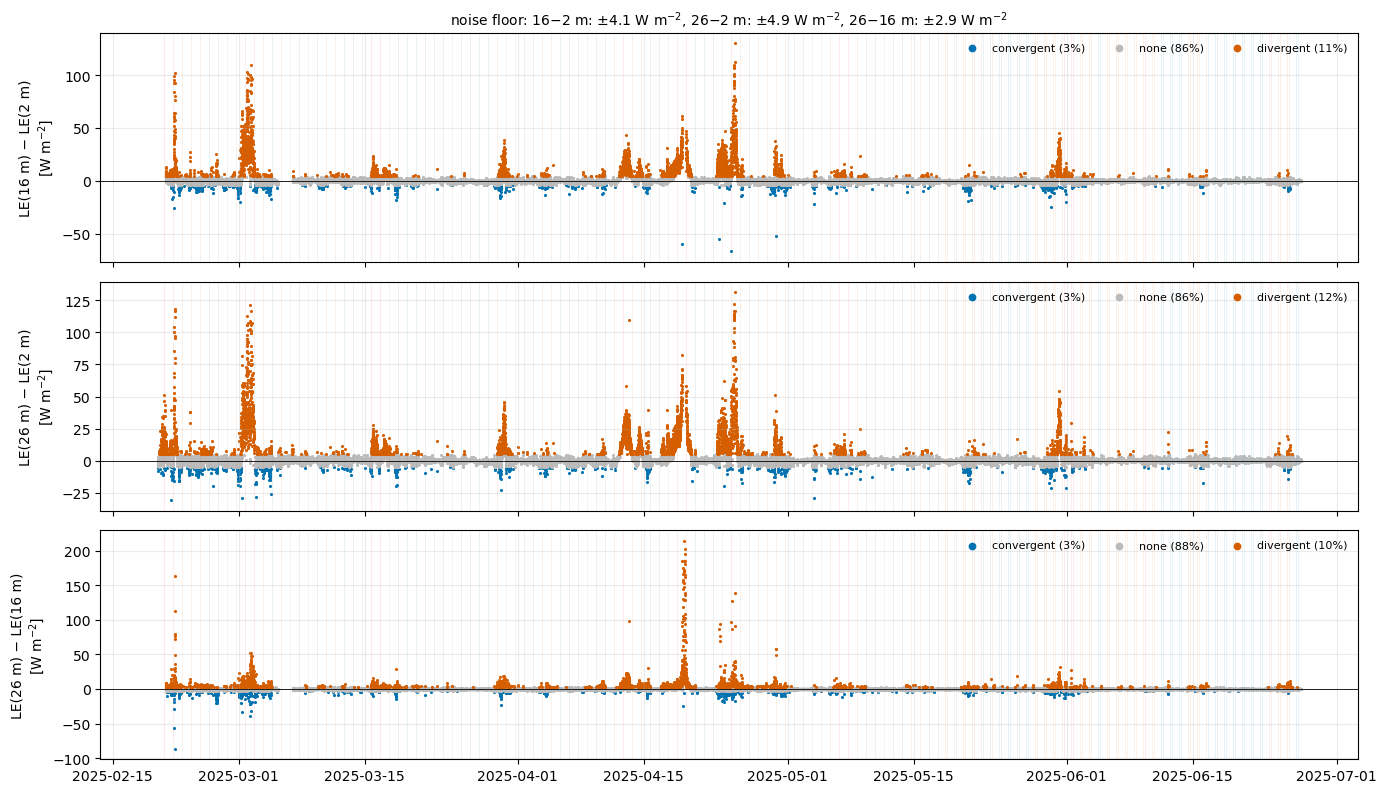

In [240]:
"""CATEGORY TIME SERIES: dLE per pair, coloured by category, regime as background shading"""

fig, axes = plot_category_strip(tab, cats, regime_colors=regime_colors)
axes[0, 0].set_title('noise floor: ' + ', '.join(f'{p.replace("_", "−")} m: ±{noise_thr[p]:.1f} W m$^{{-2}}$' for p in pair_tags),
                     fontsize=10)
plt.show()

In [241]:
"""OCCURRENCE: share of time in each category, split by blowing snow, regime and stability"""

occ = {}
for pair in pair_tags:
    parts = []
    for by, name in [('bs', 'blowing snow'), ('regime', 'regime'), ('stability', 'SFC stability')]:
        t = occurrence_table(tab, cats[pair], by)
        t.index = pd.MultiIndex.from_product([[name], t.index.map(lambda v: {True: 'yes', False: 'no'}.get(v, v))])
        parts.append(t)
    occ[pair] = pd.concat(parts)

occ_all = pd.concat(occ, axis=1)
occ_all.style.format({c: '{:.0%}' for c in occ_all.columns if c[1] != 'n'} | {c: '{:.0f}' for c in occ_all.columns if c[1] == 'n'})

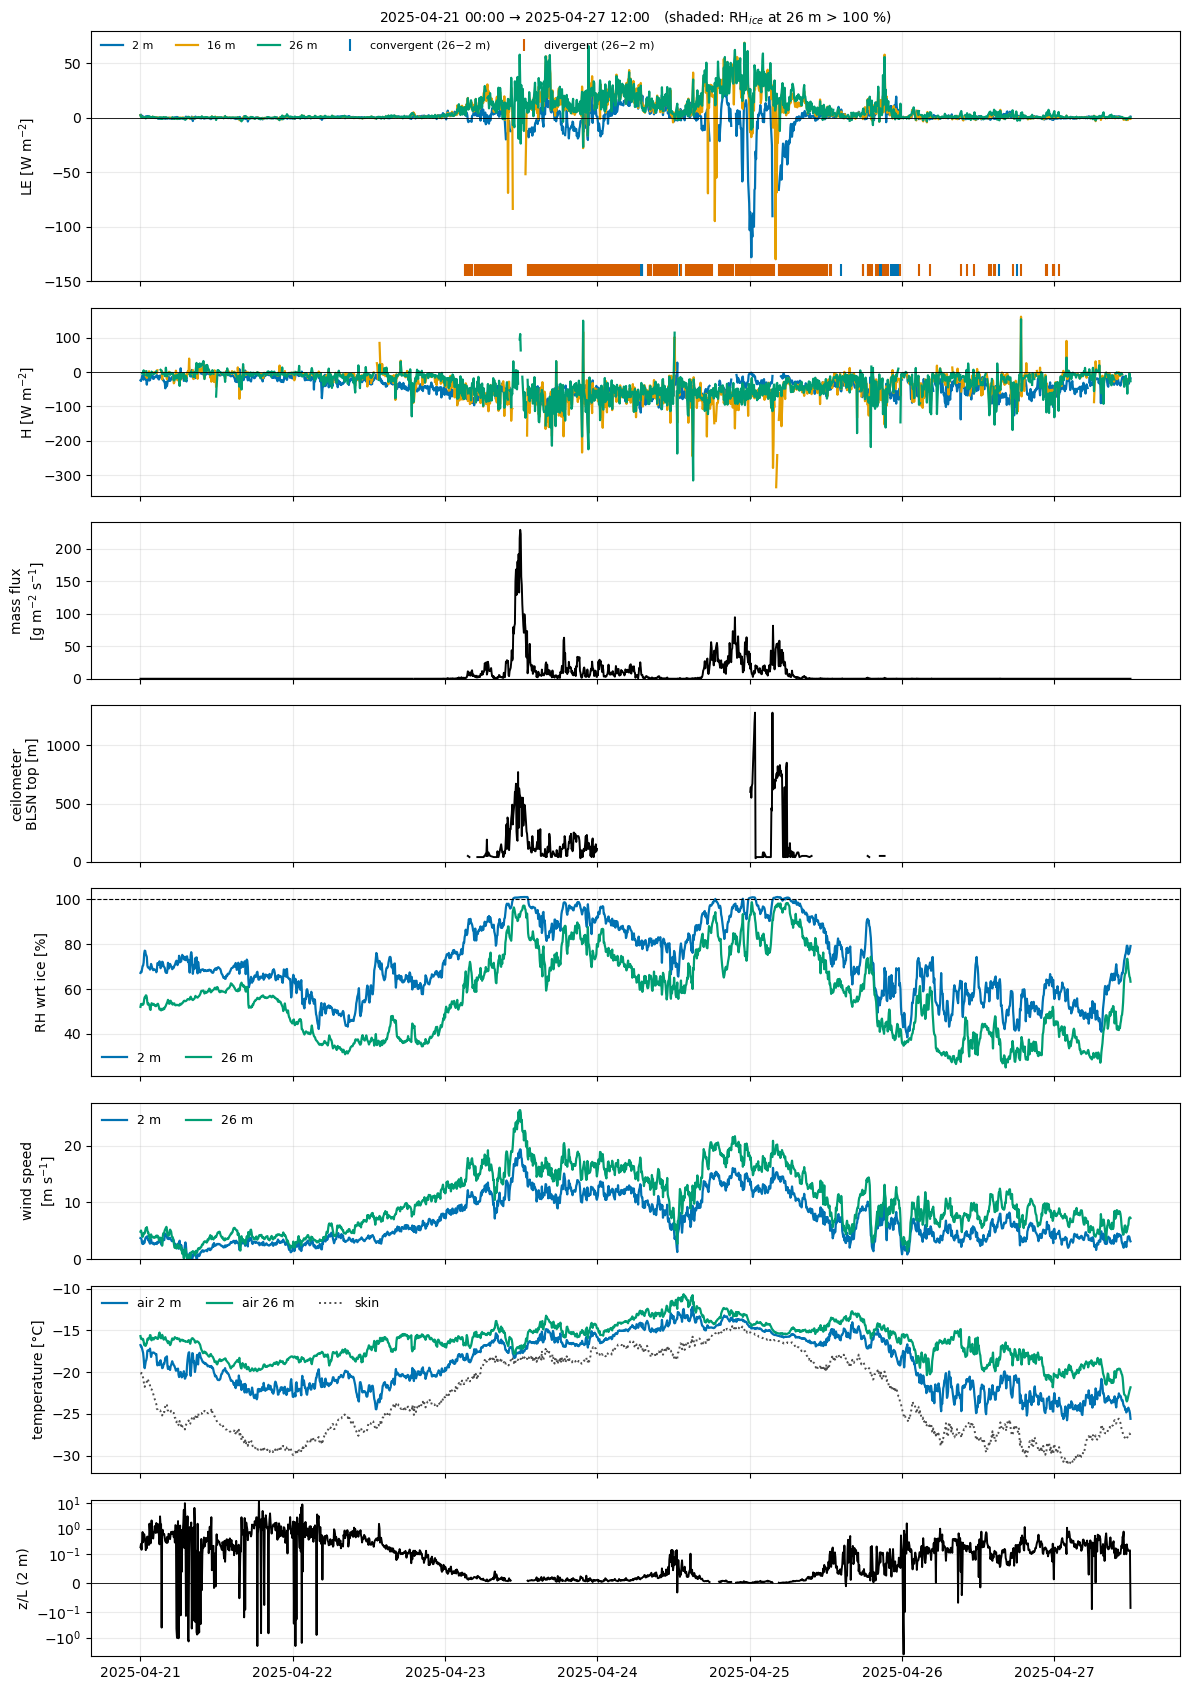

In [242]:
"""EVENT TIME SERIES: LE and H per level, drift (FlowCapt, ceilometer), RH wrt ice, wind, temperatures
and stability for the window `check_event`. Shading marks ice supersaturation at 26 m; the ticks under the
LE panel mark convergent / divergent steps of the focus pair. Default window: the 2–3 March 2025 event,
where the profile briefly turns convergent (deposition growing with height) during a drift-free lull."""

fig, axes = plot_event_timeseries(tab, *check_event, cats=cats, pair=focus_pair,
                                  height_colors={'2m': colors['SFC'], '16m': colors['16m'], '26m': colors['26m']})
plt.show()


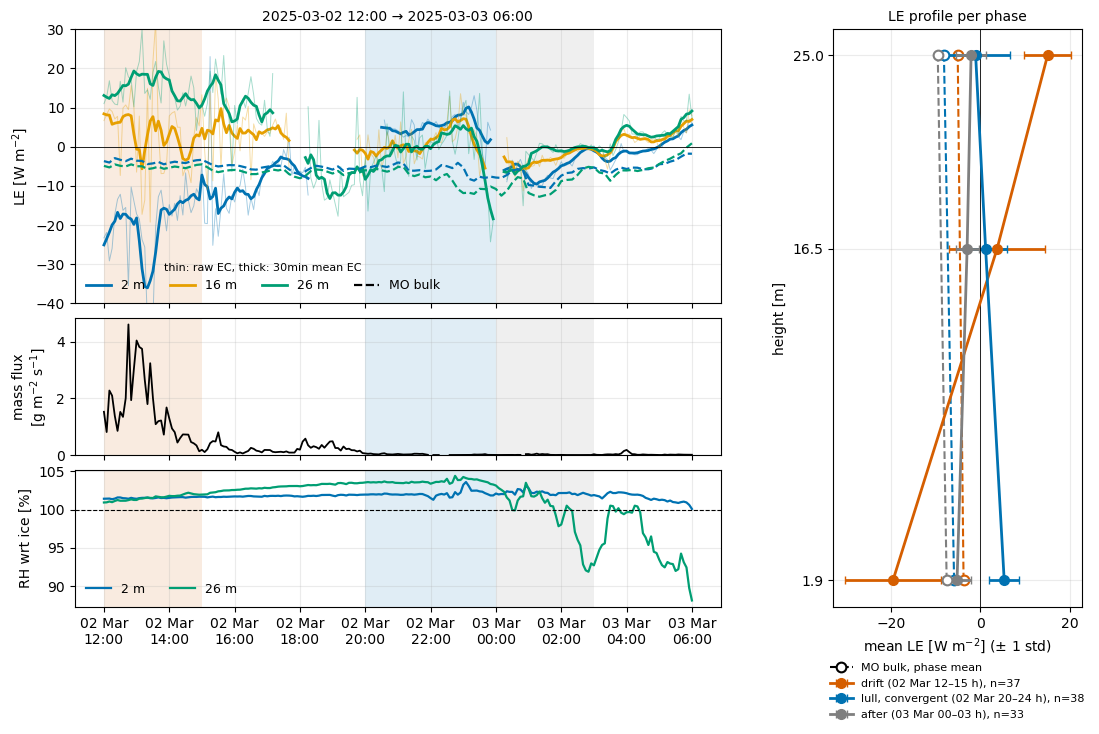

In [243]:
"""EVENT ZOOM: LE per level with a 30 min running mean, drift flux and RH wrt ice for `zoom_event`,
plus the mean LE profile per phase in `zoom_phases`. Default: the 2 March 2025 lull, where the drift stops,
26 m stays ice-supersaturated and the profile turns from divergent to convergent (deposition growing with
height) for a few hours. The MO bulk fluxes of `mo_csv` (2 m and 26 m, converged steps only) are drawn as
dashed lines in the same colours, and as open markers in the profile panel."""

mo_fluxes = load_mo_fluxes(mo_csv) if mo_csv else None
fig, axes = plot_event_zoom(tab, *zoom_event, phases=zoom_phases, sonic_heights=sonic_heights,
                            height_colors={'2m': colors['SFC'], '16m': colors['16m'], '26m': colors['26m']},
                            le_ylim=(-40, 30), mo=mo_fluxes)
plt.show()


## 5. Is it a blowing-snow effect? Composites

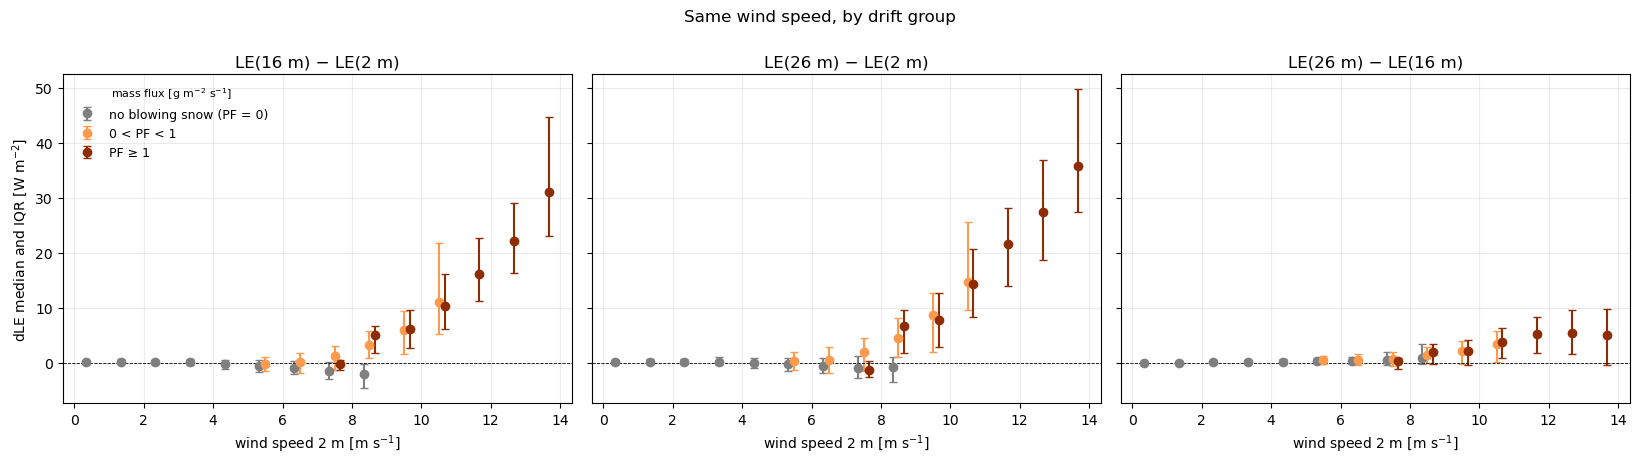

median                                             \
pair                       16_2                                      26_16   
group  no blowing snow (PF = 0) 0 < PF < 1 PF ≥ 1 no blowing snow (PF = 0)   
ws_bin                                                                       
0.5                         0.1        NaN    NaN                      0.0   
1.5                         0.1        NaN    NaN                      0.0   
2.5                         0.1        NaN    NaN                      0.1   
3.5                         0.1        NaN    NaN                      0.1   
4.5                        -0.2        NaN    NaN                      0.2   
5.5                        -0.6       -0.3    NaN                      0.3   
6.5                        -0.9        0.1    NaN                      0.3   
7.5                        -1.6        1.2   -0.3                      0.5   
8.5                        -2.1        3.2    5.0                      0.9   
9.5                         NaN        6.0    6.2                      NaN   
10.5                        NaN       11.1   10.4                      NaN   
11.5                        NaN        NaN   16.1                      NaN   
12.5                        NaN        NaN   22.0                      NaN   
13.5                        NaN        NaN   31.0                      NaN   

                                                                     \
pair                                         26_2                     
group  0 < PF < 1 PF ≥ 1 no blowing snow (PF = 0) 0 < PF < 1 PF ≥ 1   
ws_bin                                                                
0.5           NaN    NaN                      0.1        NaN    NaN   
1.5           NaN    NaN                      0.1        NaN    NaN   
2.5           NaN    NaN                      0.2        NaN    NaN   
3.5           NaN    NaN                      0.2        NaN    NaN   
4.5           NaN    NaN                     -0.0        NaN    NaN   
5.5           0.4    NaN                     -0.2        0.3    NaN   
6.5           0.6    NaN                     -0.6        0.5    NaN   
7.5           0.7    0.2                     -0.9        1.9   -1.3   
8.5           1.4    2.0                     -0.9        4.5    6.7   
9.5           2.1    2.0                      NaN        8.6    7.8   
10.5          3.5    3.7                      NaN       14.7   14.3   
11.5          NaN    5.1                      NaN        NaN   21.5   
12.5          NaN    5.4                      NaN        NaN   27.3   
13.5          NaN    5.0                      NaN        NaN   35.8   

                              n                                             \
pair                       16_2                                      26_16   
group  no blowing snow (PF = 0) 0 < PF < 1 PF ≥ 1 no blowing snow (PF = 0)   
ws_bin                                                                       
0.5                      1227.0        0.0    0.0                   1252.0   
1.5                      2867.0        0.0    0.0                   2822.0   
2.5                      4470.0        0.0    0.0                   4352.0   
3.5                      5645.0        0.0    0.0                   5402.0   
4.5                      4785.0        0.0    0.0                   4585.0   
5.5                      2738.0     1166.0    0.0                   2645.0   
6.5                      1020.0     1539.0    0.0                    994.0   
7.5                       231.0     1217.0   20.0                    226.0   
8.5                        51.0      890.0  121.0                     51.0   
9.5                         7.0      547.0  316.0                      7.0   
10.5                        0.0      174.0  613.0                      0.0   
11.5                        0.0        9.0  524.0                      0.0   
12.5                        0.0        0.0  361.0                      0.0   
13.5           

In [244]:
"""SAME WIND SPEED, BY DRIFT GROUP.
Wind and drift are collinear, so this is the direct test: inside one wind-speed bin, does dLE
differ between half-hours without drift, with weak drift and with stronger drift?
Groups come from `matched_pf_thresholds` in the config cell: PF_FC4 = 0, 0 < PF < 0.01, PF >= 0.01."""

fig, axes, matched = plot_matched_wind(tab, pair_tags, ws_col='WS_2m', bin_width=ws_bin_width,
                                       pf_thresholds=matched_pf_thresholds)
plt.show()
matched.pivot_table(index='ws_bin', columns=['pair', 'group'], values=['median', 'n'], observed=False).round(1)

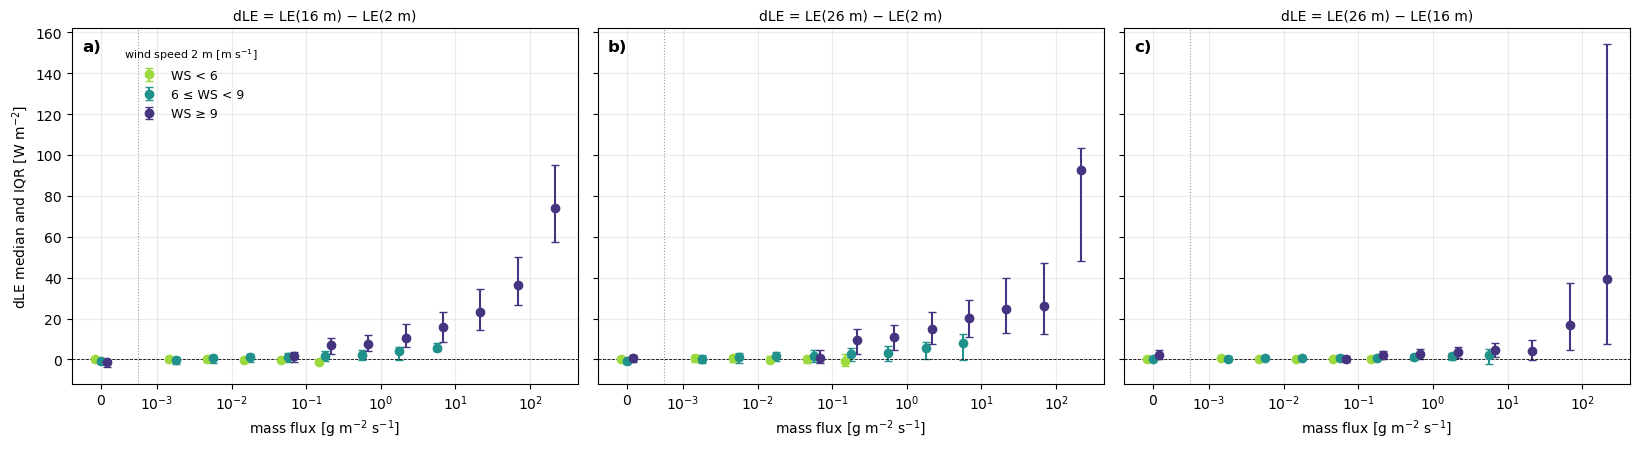

median                                                    \
pair            16_2                    26_16                     26_2   
group         WS < 6 6 ≤ WS < 9 WS ≥ 9 WS < 6 6 ≤ WS < 9 WS ≥ 9 WS < 6   
pf_bin                                                                   
no drift         0.0       -1.0   -1.0    0.1        0.3    2.1    0.1   
0.001–0.0032     0.1       -0.5    NaN    0.6        0.3    NaN    0.6   
0.0032–0.01      0.1        0.7    NaN    0.4        0.7    NaN    0.6   
0.01–0.032      -0.4        1.0    NaN    0.2        0.7    NaN   -0.1   
0.032–0.1       -0.4        1.1    1.6    0.1        0.8   -0.0    0.1   
0.1–0.32        -1.3        1.8    6.9    0.4        0.9    2.3   -0.9   
0.32–1           NaN        2.3    7.7    NaN        1.3    2.6    NaN   
1–3.2            NaN        4.0   10.6    NaN        1.7    3.6    NaN   
3.2–10           NaN        5.8   15.7    NaN        2.0    4.7    NaN   
10–32            NaN        NaN   23.2    NaN        NaN    4.2    NaN   
32–1e+02         NaN        NaN   36.5    NaN        NaN   16.6    NaN   
1e+02–3.2e+02    NaN        NaN   74.1    NaN        NaN   39.6    NaN   

                                       n                             \
pair                                16_2                      26_16   
group         6 ≤ WS < 9 WS ≥ 9   WS < 6 6 ≤ WS < 9 WS ≥ 9   WS < 6   
pf_bin                                                                
no drift            -0.6    0.9  21826.0     1302.0   10.0  21141.0   
0.001–0.0032        -0.0    NaN    192.0      237.0    3.0    188.0   
0.0032–0.01          1.2    NaN    237.0      397.0    5.0    237.0   
0.01–0.032           1.5    NaN    261.0      565.0    8.0    255.0   
0.032–0.1            1.7    0.7    147.0      781.0   39.0    138.0   
0.1–0.32             2.6    9.6     13.0      893.0  180.0     13.0   
0.32–1               3.2   10.8      1.0      468.0  492.0      1.0   
1–3.2                5.6   14.8      0.0      118.0  854.0      0.0   
3.2–10               7.8   20.5      0.0       22.0  745.0      0.0   
10–32                NaN   24.5      0.0        1.0  373.0      0.0   
32–1e+02             NaN   26.0      0.0        0.0   79.0      0.0   
1e+02–3.2e+02        NaN   92.8      0.0        0.0   10.0      0.0   

                                                            
pair                                26_2                    
group         6 ≤ WS < 9 WS ≥ 9   WS < 6 6 ≤ WS < 9 WS ≥ 9  
pf_bin                                                      
no drift          1271.0   15.0  22837.0     1301.0   10.0  
0.001–0.0032       226.0    3.0    192.0      227.0    3.0  
0.0032–0.01        389.0    5.0    239.0      398.0    5.0  
0.01–0.032         555.0    8.0    265.0      570.0    8.0  
0.032–0.1          768.0   39.0    144.0      778.0   39.0  
0.1–0.32           889.0  173.0     13.0      896.0  173.0  
0.32–1             469.0  490.0      1.0      485.0  490.0  
1–3.2              118.0  853.0      0.0      125.0  875.0  
3.2–10              22.0  746.0      0.0       23.0  777.0  
10–32                1.0  403.0      0.0        2.0  439.0  
32–1e+02             0.0  204.0      0.0        0.0  132.0  
1e+02–3.2e+02        0.0   25.0      0.0        0.0   10.0

In [245]:
"""SAME DRIFT MASS FLUX, BY WIND-SPEED GROUP.
The mirror of the cell above: blowing-snow mass flux PF_FC4 on the x-axis (log bins), and inside
one drift bin the half-hours are split by wind speed. If dLE follows the drift flux regardless of
wind group, drift is the better predictor; if the wind groups separate at the same drift flux,
wind matters on its own. Half-hours without drift are drawn at the far left ("0").
Groups come from `matched_ws_thresholds` in the config cell."""

fig, axes, matched_drift = plot_matched_drift(tab, pair_tags, log_bin_width=pf_log_bin_width, pf_min=matched_pf_min,
                                              ws_thresholds=matched_ws_thresholds, ws_col='WS_2m')
plt.savefig(f'{save_plots}/le_div_flux_{year}.png', dpi=300, bbox_inches='tight')
plt.show()
matched_drift.pivot_table(index='pf_bin', columns=['pair', 'group'], values=['median', 'n'], observed=False).round(1)

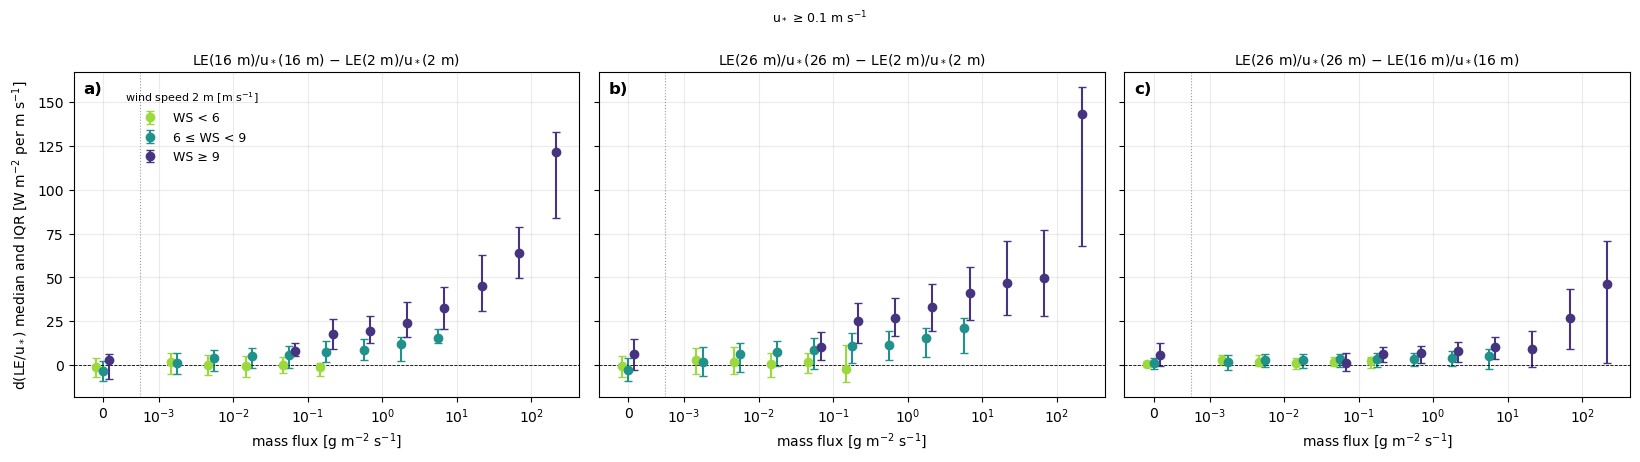

median                                                    \
pair            16_2                    26_16                     26_2   
group         WS < 6 6 ≤ WS < 9 WS ≥ 9 WS < 6 6 ≤ WS < 9 WS ≥ 9 WS < 6   
pf_bin                                                                   
no drift        -1.0       -3.4    2.9    0.5        1.0    6.0   -0.3   
0.001–0.0032     1.9        1.1    NaN    2.7        1.5    NaN    2.8   
0.0032–0.01      0.2        4.2    NaN    2.0        3.1    NaN    1.9   
0.01–0.032      -0.7        5.1    NaN    1.1        3.0    NaN    0.6   
0.032–0.1        0.0        5.4    8.1    1.4        3.2    1.4    1.4   
0.1–0.32        -1.1        7.5   17.4    2.1        3.3    6.2   -2.3   
0.32–1           NaN        8.8   19.3    NaN        3.7    6.7    NaN   
1–3.2            NaN       12.0   23.7    NaN        3.8    7.9    NaN   
3.2–10           NaN       15.6   32.4    NaN        5.1   10.1    NaN   
10–32            NaN        NaN   45.1    NaN        NaN    9.1    NaN   
32–1e+02         NaN        NaN   63.7    NaN        NaN   26.9    NaN   
1e+02–3.2e+02    NaN        NaN  121.4    NaN        NaN   46.2    NaN   

                                       n                             \
pair                                16_2                      26_16   
group         6 ≤ WS < 9 WS ≥ 9   WS < 6 6 ≤ WS < 9 WS ≥ 9   WS < 6   
pf_bin                                                                
no drift            -3.0    6.0  10361.0     1221.0   10.0  13929.0   
0.001–0.0032         2.0    NaN    178.0      230.0    3.0    168.0   
0.0032–0.01          6.1    NaN    225.0      393.0    5.0    219.0   
0.01–0.032           7.6    NaN    236.0      559.0    8.0    225.0   
0.032–0.1            8.4   10.5    134.0      765.0   39.0    122.0   
0.1–0.32            10.7   25.1     13.0      873.0  180.0     13.0   
0.32–1              11.6   27.0      1.0      467.0  492.0      1.0   
1–3.2               15.5   33.2      0.0      117.0  854.0      0.0   
3.2–10              21.4   41.1      0.0       22.0  745.0      0.0   
10–32                NaN   47.0      0.0        1.0  373.0      0.0   
32–1e+02             NaN   49.5      0.0        0.0   79.0      0.0   
1e+02–3.2e+02        NaN  143.4      0.0        0.0   10.0      0.0   

                                                            
pair                                26_2                    
group         6 ≤ WS < 9 WS ≥ 9   WS < 6 6 ≤ WS < 9 WS ≥ 9  
pf_bin                                                      
no drift          1158.0   15.0  11036.0     1245.0   10.0  
0.001–0.0032       215.0    3.0    182.0      220.0    3.0  
0.0032–0.01        379.0    5.0    226.0      391.0    5.0  
0.01–0.032         539.0    8.0    246.0      556.0    8.0  
0.032–0.1          745.0   39.0    134.0      763.0   39.0  
0.1–0.32           854.0  172.0     13.0      876.0  172.0  
0.32–1             466.0  490.0      1.0      483.0  490.0  
1–3.2              116.0  852.0      0.0      124.0  874.0  
3.2–10              22.0  746.0      0.0       23.0  777.0  
10–32                1.0  403.0      0.0        2.0  439.0  
32–1e+02             0.0  204.0      0.0        0.0  132.0  
1e+02–3.2e+02        0.0   25.0      0.0        0.0   10.0

In [246]:
"""SAME DRIFT MASS FLUX, BY WIND-SPEED GROUP, WITH LE DIVIDED BY THE MEASURED u*.
As the cell above, but every LE is first divided by the friction velocity of its own sonic in the same
half-hour (y = LE(up)/u*(up) − LE(lo)/u*(lo), `ustar='local'`; `ustar='2m'` divides both by the 2 m value
instead). This takes the common growth of all fluxes with turbulence out, so a remaining trend with drift
flux is a change of the exchange per unit u*, not more turbulence. Half-hours with u* below `sfl_ustar_min`
at either level are dropped. Needs the `ustar_<lvl>` columns: rebuild `tab` (section 3) if they are missing."""

fig, axes, matched_drift_ustar = plot_matched_drift(tab, pair_tags, log_bin_width=pf_log_bin_width, pf_min=matched_pf_min,
                                                    ws_thresholds=matched_ws_thresholds, ws_col='WS_2m',
                                                    ustar='local', ustar_min=sfl_ustar_min)
plt.savefig(f'{save_plots}/le_div_flux_ustar_{year}.png', dpi=300, bbox_inches='tight')
plt.show()
matched_drift_ustar.pivot_table(index='pf_bin', columns=['pair', 'group'], values=['median', 'n'], observed=False).round(1)


{'2m': 'baseline 247, 6096 half-hours', '16m': 'baseline 247, 5975 half-hours', '26m': 'baseline 248, 6096 half-hours'}


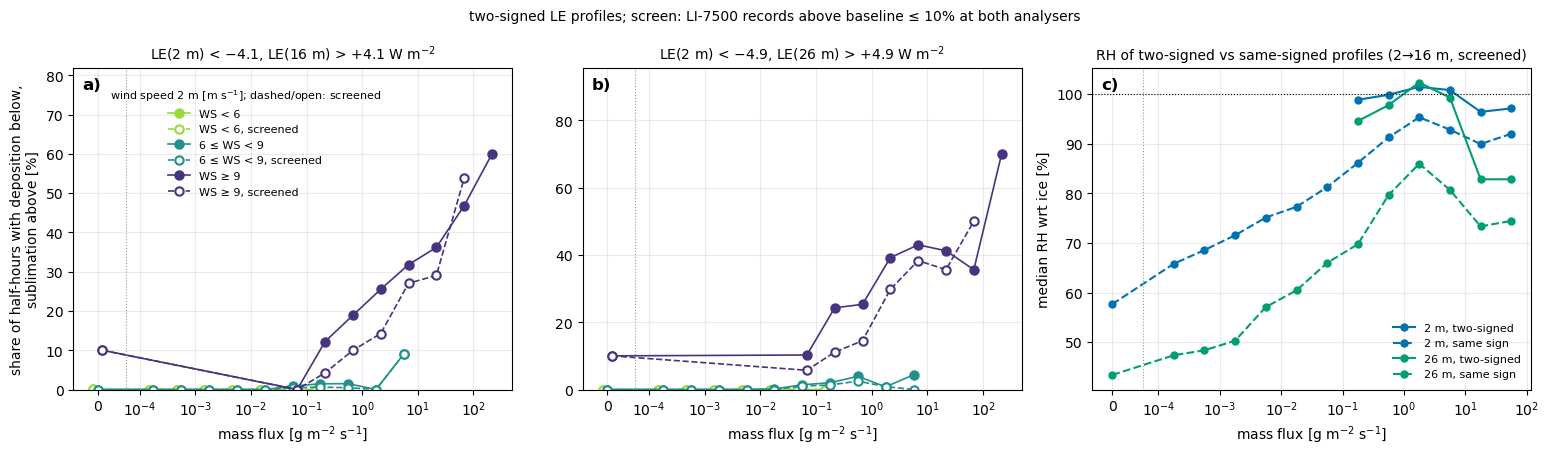

n        n_flip        frac      
screened             False  True   False True  False True 
pair pf_bin                                               
16_2 no drift        23138  22556      3     3  0.00  0.00
     0.0001–0.00032    213    181      0     0  0.00  0.00
     0.00032–0.001     410    348      0     0  0.00  0.00
     0.001–0.0032      432    369      0     0  0.00  0.00
     0.0032–0.01       639    531      0     0  0.00  0.00
     0.01–0.032        834    719      0     0  0.00  0.00
     0.032–0.1         967    872      7     3  0.01  0.00
     0.1–0.32         1086    970     35    11  0.03  0.01
     0.32–1            961    841    100    42  0.10  0.05
     1–3.2             972    786    218    96  0.22  0.12
     3.2–10            767    610    239   163  0.31  0.27
     10–32             374    234    135    68  0.36  0.29
     32–1e+02           79     26     37    14  0.47  0.54
     1e+02–3.2e+02      10      0      6     0  0.60   NaN
26_2 no drift        24148  23550      2     2  0.00  0.00
     0.0001–0.00032    212    180      0     0  0.00  0.00
     0.00032–0.001     407    345      0     0  0.00  0.00
     0.001–0.0032      422    362      0     0  0.00  0.00
     0.0032–0.01       642    537      0     0  0.00  0.00
     0.01–0.032        843    729      1     0  0.00  0.00
     0.032–0.1         961    866     15     9  0.02  0.01
     0.1–0.32         1082    966     60    26  0.06  0.03
     0.32–1            976    843    143    69  0.15  0.08
     1–3.2            1000    785    344   201  0.34  0.26
     3.2–10            800    609    335   229  0.42  0.38
     10–32             441    233    181    83  0.41  0.36
     32–1e+02          132     26     47    13  0.36  0.50
     1e+02–3.2e+02      10      0      7     0  0.70   NaN

In [247]:
"""TWO-SIGNED LE PROFILES: deposition at the lower level and sublimation at the upper one in the same half-hour.
A sign change between two levels needs a vapour source in between: scaling of a single flux with wind or u* cannot
produce it, so this is the evidence that the divergence under drift is sublimation of drifting snow, not larger
fluxes. Both |LE| must exceed the pair's noise floor. Filled: all half-hours; open/dashed: only half-hours that pass
the LI-7500 signal-strength screen (`agc_max_share`) at both analysers of the pair, because the strongest 2 m
deposition values occur when the open path is loaded with particles (see the surface flux law tail). The last panel
checks the physics: the two-signed cases should have RH over ice near 100 % at 2 m and clearly below it at 26 m.
The diagnostic is read from the Peddy fast files once per sensor and cached in `agc_cache_dir`."""

diag = {lvl: li7500_diag_halfhourly(folder_ec, sensor, div_start, div_end,
                                    cache_file=f'{agc_cache_dir}/li7500_diag_{sensor}_{year}.csv')
        for lvl, sensor in [('2m', 'SFC'), ('16m', 'LOWER'), ('26m', 'UPPER')]}
print({lvl: f"baseline {d.attrs['baseline']}, {d['share_above'].notna().sum()} half-hours" for lvl, d in diag.items()})

fig, axes, two_signed = two_signed_profiles(tab, flip_pairs, diag, le_floor=noise_thr, max_share=agc_max_share,
                                            log_bin_width=pf_log_bin_width, ws_thresholds=matched_ws_thresholds,
                                            ws_col='WS_2m')
plt.savefig(f'{save_plots}/le_two_signed_{year}.png', dpi=300, bbox_inches='tight')
plt.show()
two_signed_summary(two_signed).round(2)


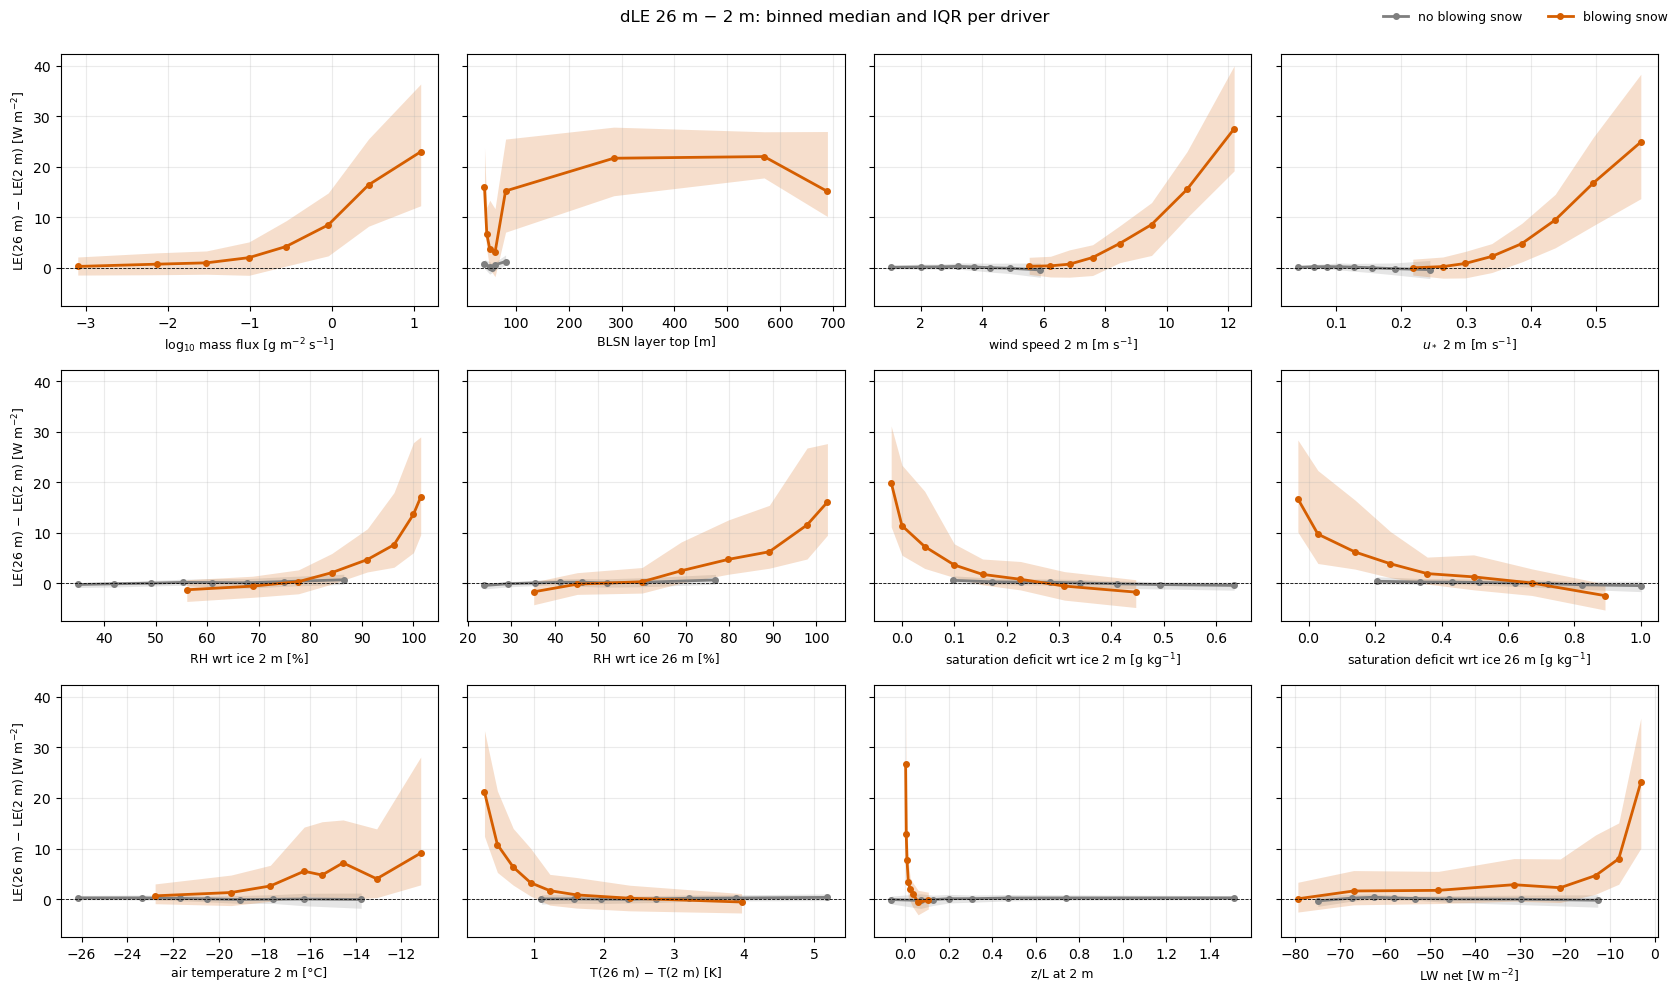

In [248]:
"""COMPOSITES for the focus pair: binned median + IQR of dLE against each driver, split by blowing snow"""

fig, axes = plot_driver_composites(tab, focus_pair, composite_drivers)
plt.show()

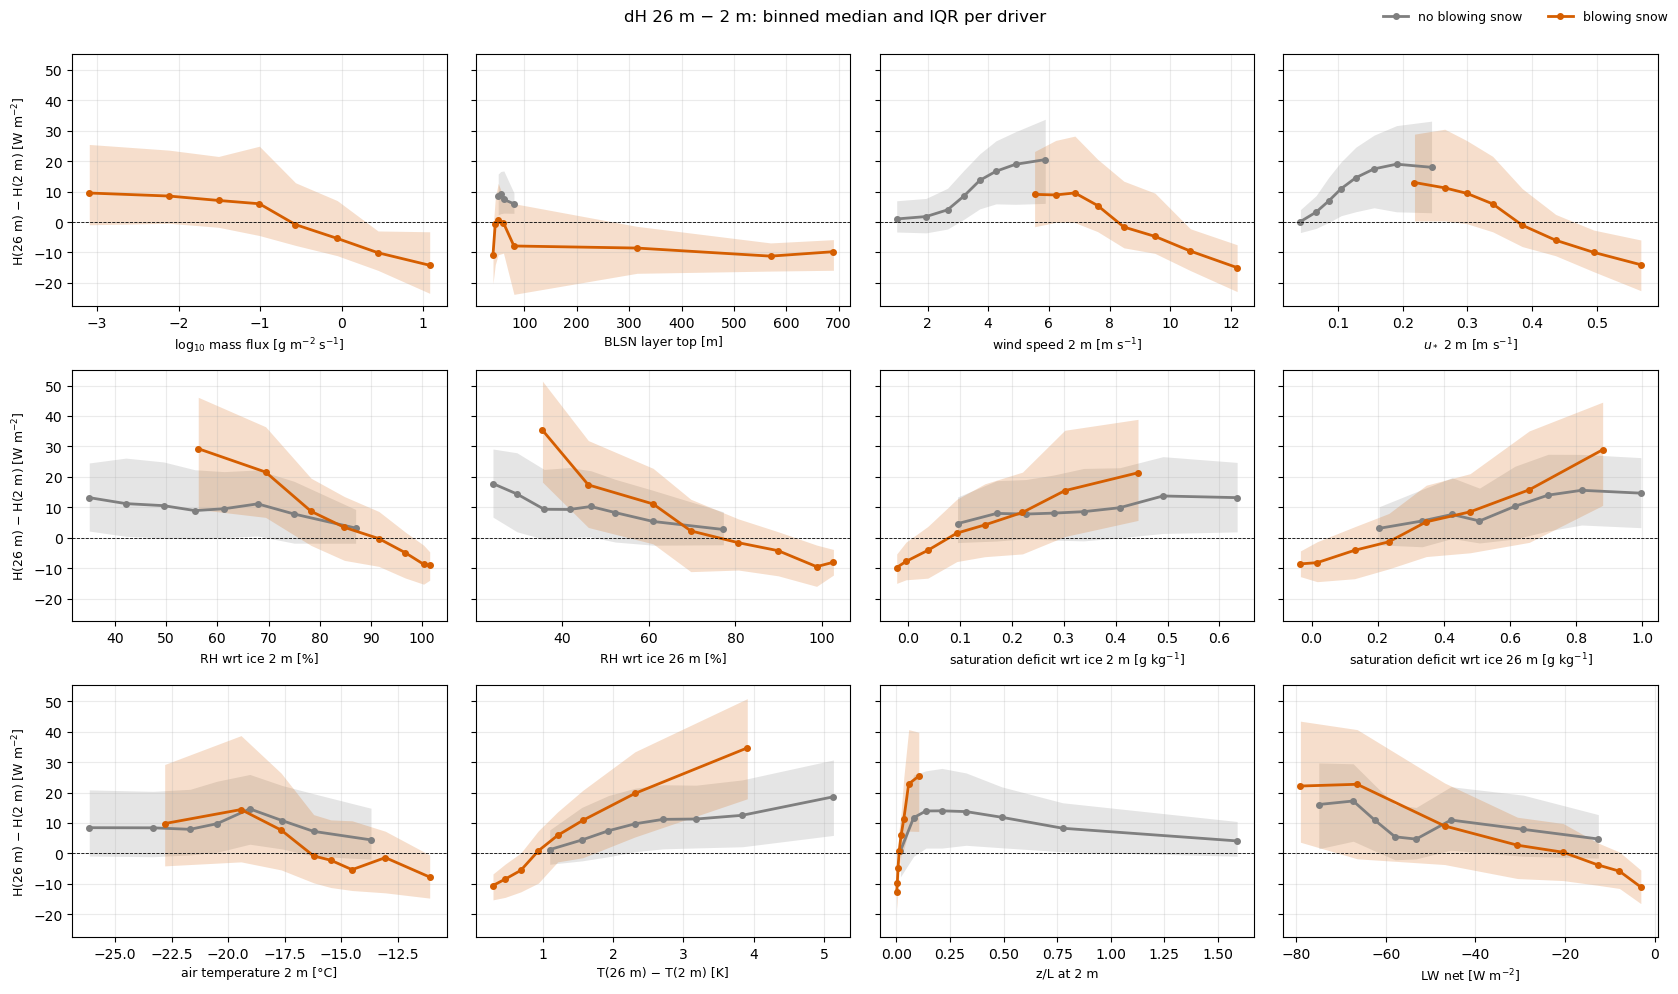

In [249]:
"""COMPOSITES for the focus pair, sensible heat: binned median + IQR of dH against each driver, split by blowing snow"""

fig, axes = plot_driver_composites(tab, focus_pair, composite_drivers, var='H')
plt.show()

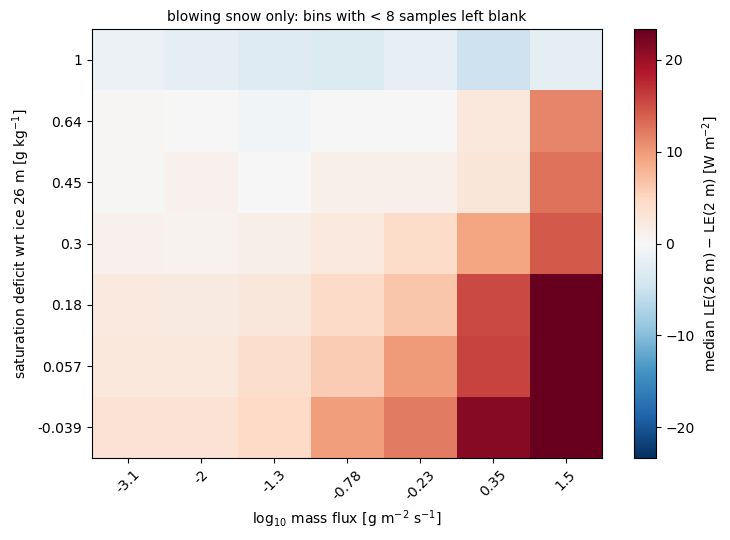

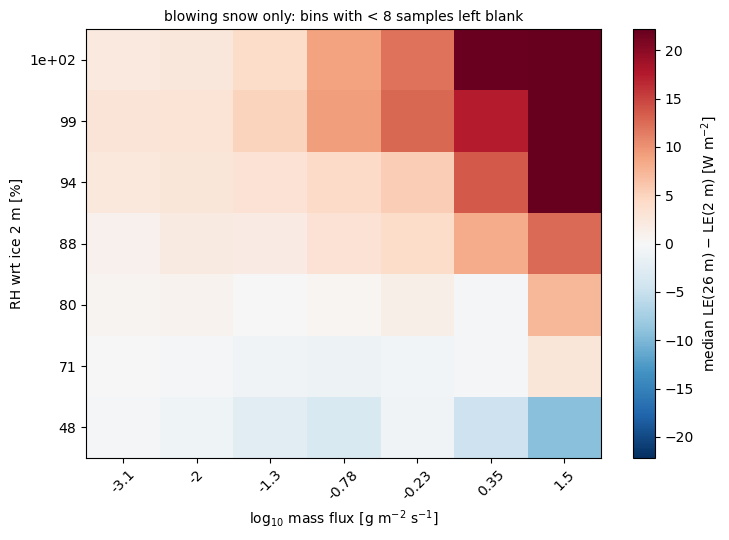

In [250]:
"""2-D MEDIANS for the focus pair (blowing-snow half-hours only):
drift strength against saturation deficit, and drift strength against wind speed"""

fig, ax, _ = plot_2d_medians(tab, focus_pair, x='logPF', y='qdef_26m')
plt.show()
fig, ax, _ = plot_2d_medians(tab, focus_pair, x='logPF', y='RHi_2m')
plt.show()

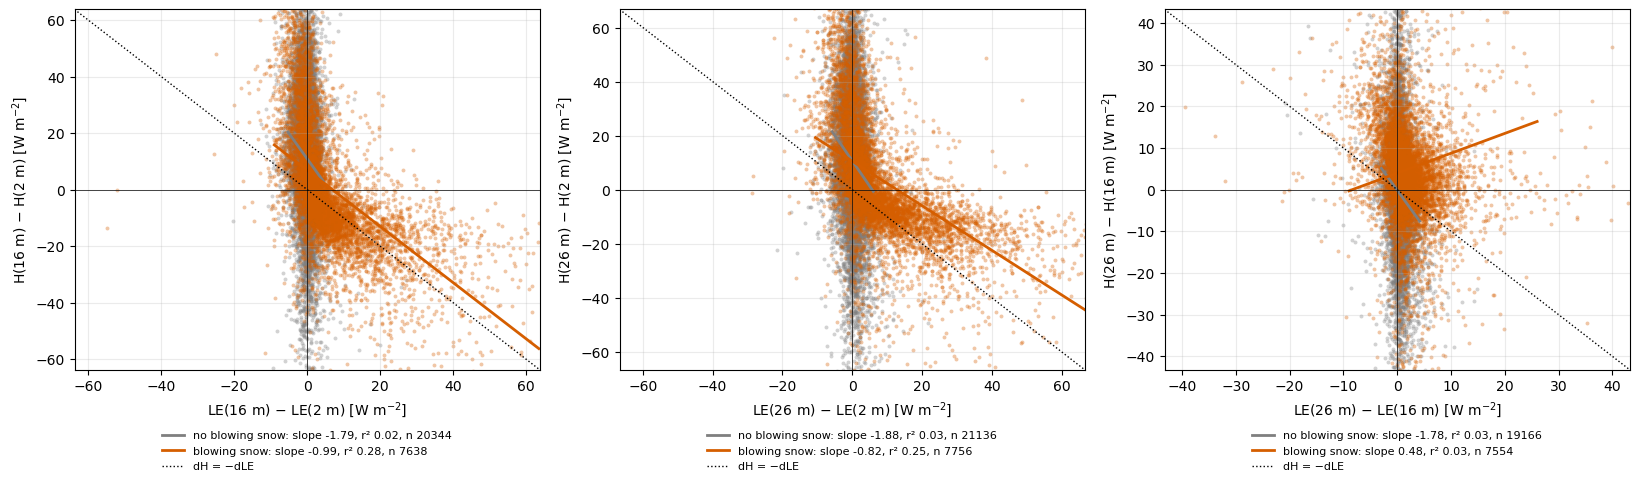

,pair,bs,slope,r2,n
0,16_2,False,-1.79,0.02,20344
1,16_2,True,-0.99,0.28,7638
2,26_2,False,-1.88,0.03,21136
3,26_2,True,-0.82,0.25,7756
4,26_16,False,-1.78,0.03,19166
5,26_16,True,0.48,0.03,7554


In [251]:
"""ENERGY CHECK: sublimation in the layer takes heat from the air, so a real sublimation signal
has dLE > 0 together with dH < 0 of similar size (points along the dotted dH = −dLE line)."""

fig, axes, energy = plot_energy_check(tab, pair_tags)
plt.show()
energy.round(2)

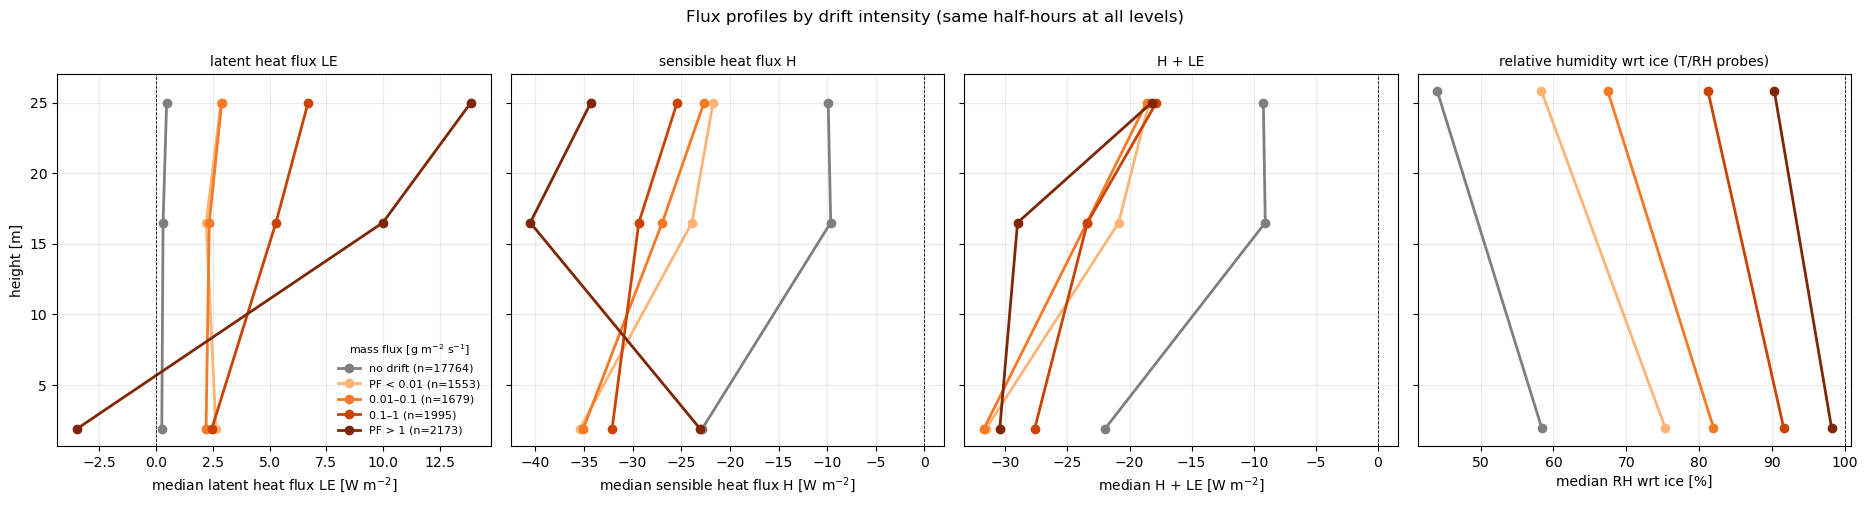

,n,WS_2m,LE_2m,LE_16m,LE_26m,H_2m,H_16m,H_26m,H+LE_2m,H+LE_16m,H+LE_26m,RHi_2m,RHi_26m,subl 2-16 m [mm w.e./day]
drift,,,,,,,,,,,,,,
no drift,17764,3.70,0.25,0.31,0.46,-22.86,-9.64,-9.90,-21.99,-9.08,-9.23,58.37,44.05,0.00
PF < 0.01,1553,6.16,2.64,2.20,2.86,-35.44,-23.90,-21.73,-31.56,-20.88,-18.43,75.32,58.35,-0.01
0.01–0.1,1679,6.79,2.20,2.34,2.89,-35.09,-26.95,-22.66,-31.74,-23.43,-18.63,81.95,67.45,0.00
0.1–1,1995,8.46,2.45,5.28,6.70,-32.11,-29.36,-25.42,-27.64,-23.39,-17.83,91.57,81.20,0.09
PF > 1,2173,11.05,-3.50,9.99,13.87,-23.05,-40.52,-34.29,-30.45,-29.02,-18.21,98.15,90.31,0.41


In [252]:
"""FLUX PROFILES BY DRIFT INTENSITY: median LE, H and H + LE at 2, 16 and 26 m.
If suspended snow sublimates between two levels, LE grows and H falls by the same amount across
that layer, and H + LE stays constant with height. Uses only half-hours valid at all three levels.
The fourth panel shows RH wrt ice at the two T/RH heights (compare Schwat et al. 2025, Fig. 5b,c)."""

fig, axes, profiles = plot_flux_profiles_by_drift(tab, sonic_heights, rh_heights=th_heights)
plt.show()

# implied sublimation rate in the 2-16 m layer: dLE / Ls, in mm water equivalent per day
Ls = 2.838e6   # J kg-1
dle = (profiles['LE_16m'] - profiles['LE_2m'])
profiles['subl 2-16 m [mm w.e./day]'] = dle / Ls * 86400
profiles.round(2)

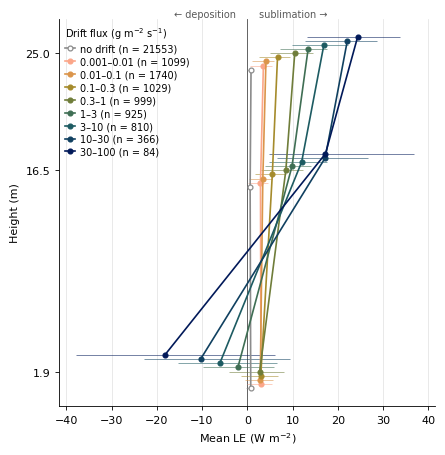

,n,PF_median,LE_2m,LE_16m,LE_26m,LE_2m_lo,LE_16m_lo,LE_26m_lo,LE_2m_hi,LE_16m_hi,LE_26m_hi
bin,,,,,,,,,,,
no drift,21553,0.00,0.76,0.62,0.82,-0.27,-0.09,-0.03,1.28,0.89,1.18
0.001–0.01,1099,0.00,3.01,2.91,3.55,-0.16,0.23,0.67,5.40,4.64,5.49
0.01–0.1,1740,0.03,2.86,3.43,4.11,-0.62,0.47,0.98,5.76,5.44,5.92
0.1–0.3,1029,0.17,2.97,5.52,6.67,-1.49,1.79,2.61,6.76,8.47,9.35
0.3–1,999,0.55,2.73,8.51,10.48,-3.96,3.02,4.96,8.03,12.25,14.42
1–3,925,1.73,-2.08,9.88,13.43,-9.82,3.86,7.14,5.81,14.11,17.54
3–10,810,4.93,-6.07,12.00,16.91,-15.42,4.80,9.80,6.65,17.62,22.22
10–30,366,15.41,-10.32,17.20,22.09,-22.75,6.54,12.71,9.39,26.56,28.56
30–100,84,40.37,-18.22,17.26,24.39,-37.76,4.78,13.14,6.16,36.91,33.63


In [270]:
"""LE PROFILE BY DRIFT FLUX, FINER BINS: the first panel of the cell above on its own, with the PF_FC4 bins of
`profile_pf_edges` instead of the five drift classes, and `profile_stat` ('mean' or 'median') per bin. Bars are the
interquartile range of the half-hours in the bin (spread='sem' gives the standard error of the mean instead); the
profiles are shifted by a quarter metre per bin so the bars stay readable. Only half-hours with LE valid at all
three levels."""

fig, ax, le_profile = plot_le_profile_by_drift(tab, sonic_heights, pf_edges=profile_pf_edges, stat=profile_stat,
                                               spread='iqr', figsize=(4.5, 4.6))
for ext in ('png', 'pdf'):   # pdf: vector version for the paper
    plt.savefig(f'{save_plots}/le_profile_by_drift_{profile_stat}_{year}.{ext}', dpi=300, bbox_inches='tight')
plt.show()
le_profile.round(2)


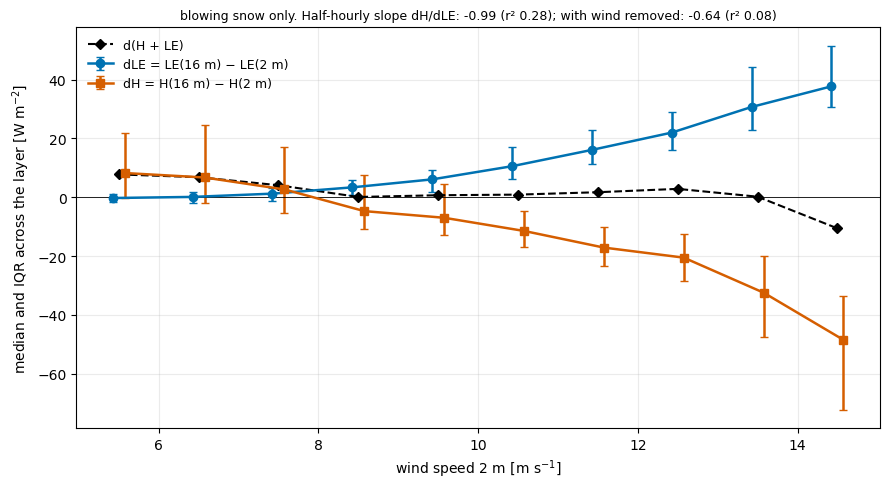

,n,dLE,dH,dSum,slope_in_bin,r2_in_bin
ws,,,,,,
5.5,1122,-0.26,8.23,7.76,-1.49,0.04
6.5,1510,0.11,6.71,6.81,-2.48,0.13
7.5,1222,1.22,2.65,4.08,-3.12,0.30
8.5,1005,3.36,-4.72,0.09,-2.31,0.31
9.5,860,6.07,-6.98,0.68,-1.55,0.26
10.5,784,10.55,-11.45,0.89,-0.60,0.23
11.5,533,16.09,-17.11,1.71,-0.49,0.18
12.5,359,21.97,-20.52,2.84,-0.27,0.06
13.5,155,30.68,-32.43,0.18,-0.40,0.15


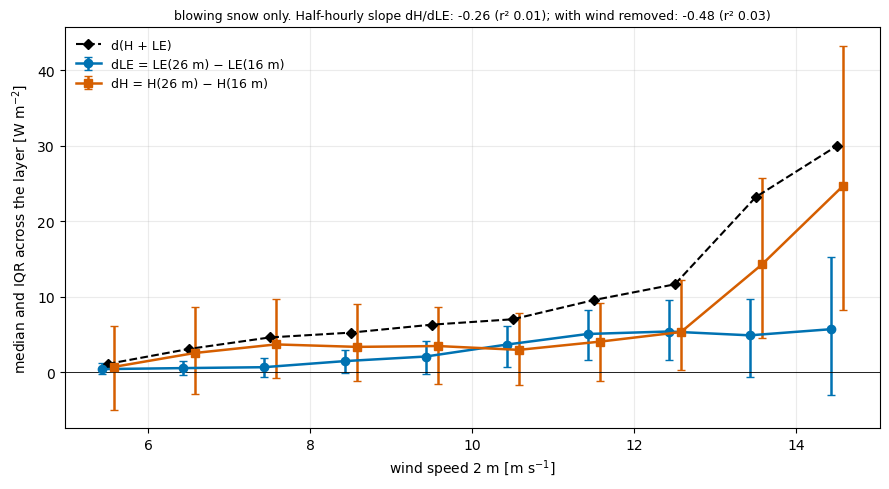

,n,dLE,dH,dSum,slope_in_bin,r2_in_bin
ws,,,,,,
5.5,1055,0.43,0.72,1.11,-1.81,0.06
6.5,1449,0.56,2.56,3.10,-1.77,0.07
7.5,1192,0.68,3.70,4.62,-1.16,0.10
8.5,997,1.49,3.37,5.26,-1.00,0.10
9.5,842,2.09,3.48,6.32,-1.05,0.19
10.5,784,3.68,2.98,7.03,-0.69,0.15
11.5,531,5.08,4.07,9.58,-0.28,0.03
12.5,357,5.41,5.34,11.66,-0.33,0.05
13.5,153,4.90,14.29,23.23,-0.20,0.02


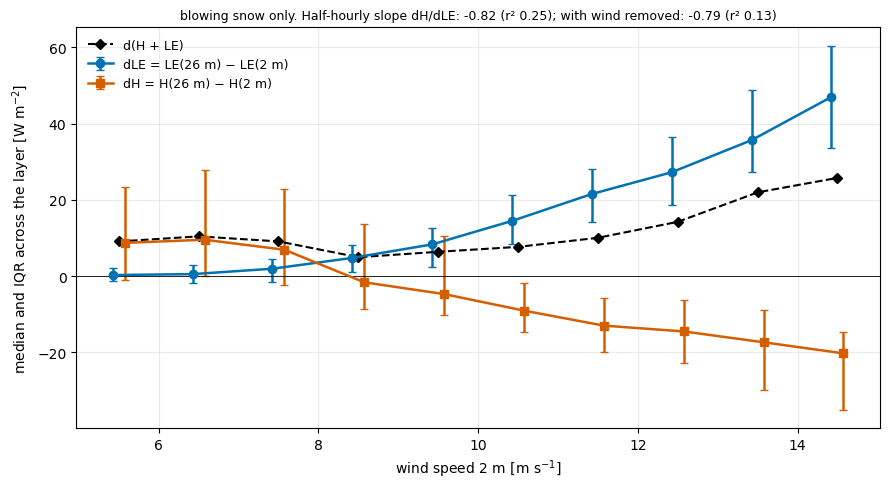

,n,dLE,dH,dSum,slope_in_bin,r2_in_bin
ws,,,,,,
5.5,1098,0.30,8.73,9.11,-1.91,0.09
6.5,1484,0.54,9.56,10.44,-2.44,0.14
7.5,1216,1.96,6.93,9.12,-2.59,0.29
8.5,1028,4.80,-1.61,4.97,-2.04,0.33
9.5,884,8.34,-4.70,6.39,-1.50,0.35
10.5,846,14.49,-9.03,7.68,-0.70,0.31
11.5,586,21.56,-12.97,10.07,-0.54,0.20
12.5,374,27.26,-14.49,14.25,-0.36,0.13
13.5,152,35.68,-17.33,21.98,-0.37,0.20


In [254]:
"""LAYER ENERGY BALANCE PER WIND-SPEED BIN (blowing snow only), for 16−2 m, 26−16 m and the full 26−2 m layer.
Sublimation predicts dLE = −dH in every wind bin, so d(H + LE) = 0. The title gives the
half-hourly slope of dH on dLE before and after removing the common wind dependence: if the
correlation vanishes once wind is removed, the evidence is in the bin medians, not in the scatter."""

for pair in ['16_2', '26_16', '26_2']:
    if pair not in pair_tags:
        continue
    fig, ax, layer = plot_layer_energy_by_wind(tab, pair, bin_width=ws_bin_width)
    plt.show()
    display(layer.round(2))

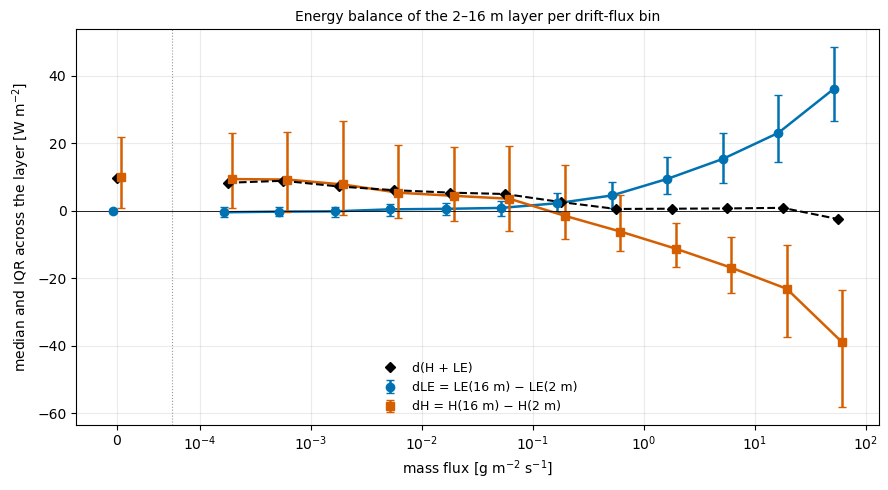

,n,WS_2m,dLE,dH,dSum
pf_bin,,,,,
no drift,20344,3.64,-0.00,9.96,9.86
0.0001–0.00032,208,5.91,-0.45,9.41,8.32
0.00032–0.001,401,6.04,-0.24,9.26,8.90
0.001–0.0032,421,6.12,-0.16,7.80,7.20
0.0032–0.01,625,6.35,0.43,5.36,6.11
0.01–0.032,811,6.50,0.58,4.43,5.39
0.032–0.1,951,7.01,0.85,3.58,4.97
0.1–0.32,1072,7.94,2.23,-1.49,2.59
0.32–1,957,9.02,4.54,-6.15,0.54


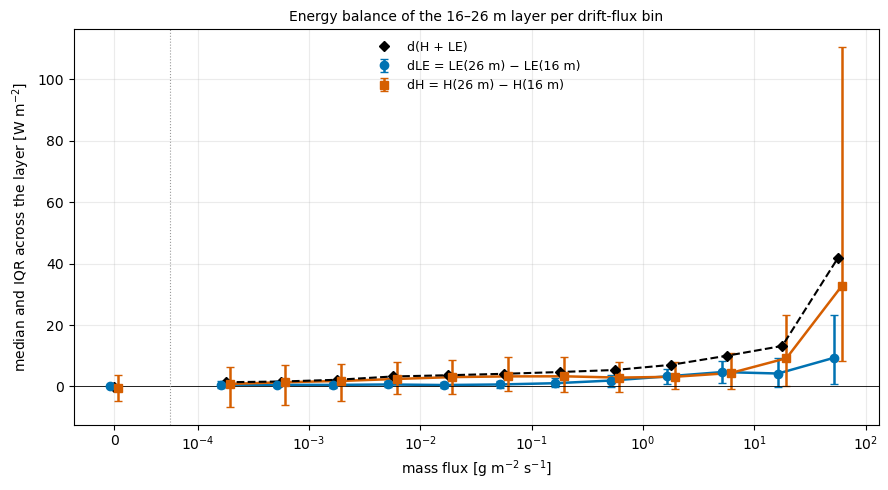

,n,WS_2m,dLE,dH,dSum
pf_bin,,,,,
no drift,19166,3.57,0.11,-0.47,-0.29
0.0001–0.00032,200,5.91,0.58,0.83,1.37
0.00032–0.001,372,6.05,0.53,1.37,1.59
0.001–0.0032,395,6.10,0.49,1.78,2.16
0.0032–0.01,596,6.35,0.63,2.43,3.23
0.01–0.032,779,6.52,0.45,3.03,3.64
0.032–0.1,926,7.02,0.63,3.26,4.11
0.1–0.32,1050,7.94,1.04,3.29,4.68
0.32–1,952,9.02,1.91,2.87,5.35


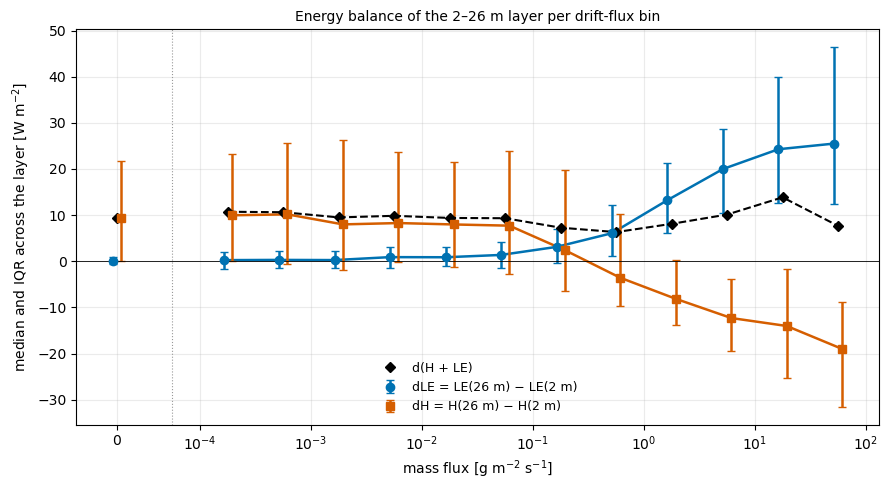

,n,WS_2m,dLE,dH,dSum
pf_bin,,,,,
no drift,21136,3.57,0.10,9.31,9.48
0.0001–0.00032,207,5.91,0.24,9.97,10.73
0.00032–0.001,388,6.05,0.29,10.16,10.63
0.001–0.0032,404,6.09,0.26,7.99,9.50
0.0032–0.01,611,6.37,0.90,8.28,9.85
0.01–0.032,810,6.50,0.87,7.97,9.39
0.032–0.1,939,7.02,1.37,7.71,9.33
0.1–0.32,1068,7.93,3.11,2.41,7.28
0.32–1,968,9.01,6.08,-3.58,6.32


In [255]:
"""LAYER ENERGY BALANCE PER DRIFT-FLUX BIN, for 16−2 m, 26−16 m and the full 26−2 m layer.
Same as the cell above, with the FlowCapt mass flux PF_FC4 on the x-axis (log bins of
`pf_log_bin_width` decades). Half-hours without drift are drawn at the far left ("0").
Sublimation predicts dLE = −dH in every drift bin, so d(H + LE) = 0. The table also gives the
median 2 m wind speed per bin, since drift flux and wind rise together."""

for pair in ['16_2', '26_16', '26_2']:
    if pair not in pair_tags:
        continue
    fig, ax, layer_drift = plot_layer_energy_by_drift(tab, pair, log_bin_width=pf_log_bin_width)
    plt.show()
    display(layer_drift.round(2))

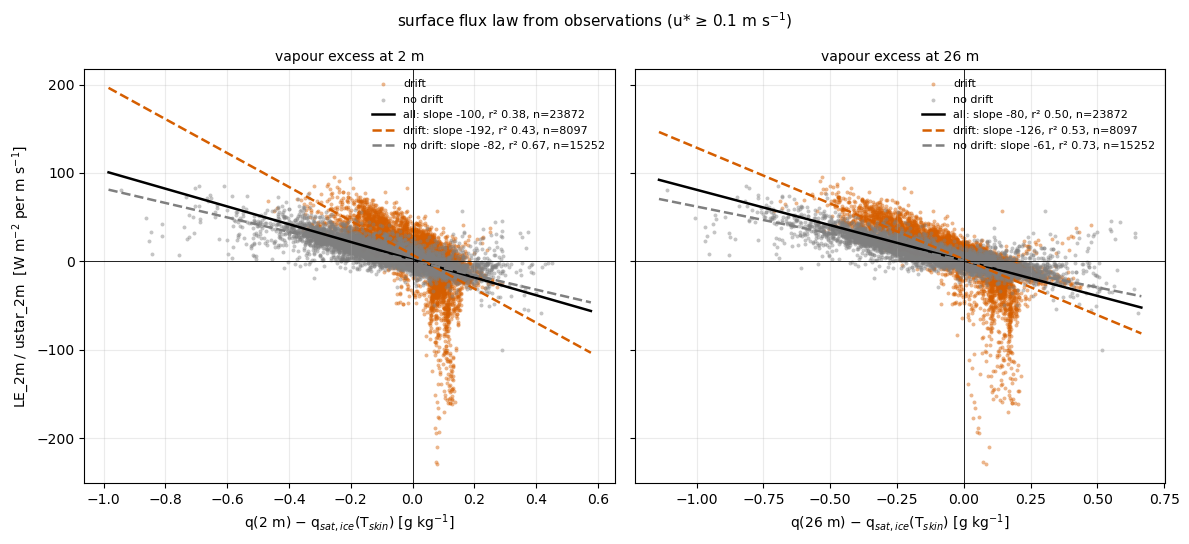

,q level,group,slope [W m-2 / (m s-1) per g/kg],intercept,r2,n
0,2m,all,-100.39,1.90,0.38,23872
1,2m,drift,-191.83,7.47,0.43,8097
2,2m,no drift,-81.65,0.75,0.67,15252
3,26m,all,-80.02,0.95,0.50,23872
4,26m,drift,-126.22,2.35,0.53,8097
5,26m,no drift,-60.95,1.07,0.73,15252


In [256]:
"""SURFACE FLUX LAW (observation version of the CRYOWRF plot_surface_flux_law figure).
y = surface LE / u* from the 2 m sonic, x = q at the probe height minus q_sat,ice at the radiometric skin
temperature. One panel per probe (2 m, 26 m; there is no 16 m probe in 2025), points split by FlowCapt
drift, least-squares line per group with slope and r² in the legend. The model (CRYOWRF d05, drift peak)
gives LE/u* ≈ −250 to −270 × dq(0.24 m) with r² > 0.99; expect a shallower slope here, 2 m being further
from the surface than the model's first level."""

fig, axes, sfl_fits = plot_surface_flux_law(tab, q_levels=sfl_q_levels, ustar_min=sfl_ustar_min,
                                            height_colors={'2m': colors['SFC'], '16m': colors['16m'], '26m': colors['26m']})
plt.show()
sfl_fits.round(2)


model: 2025-04-23 21:00:00 → 2025-04-25 12:00:00, runs ['fmprog', 'v202'], no-drift steps per run: {'fmprog': 1, 'v202': 1}


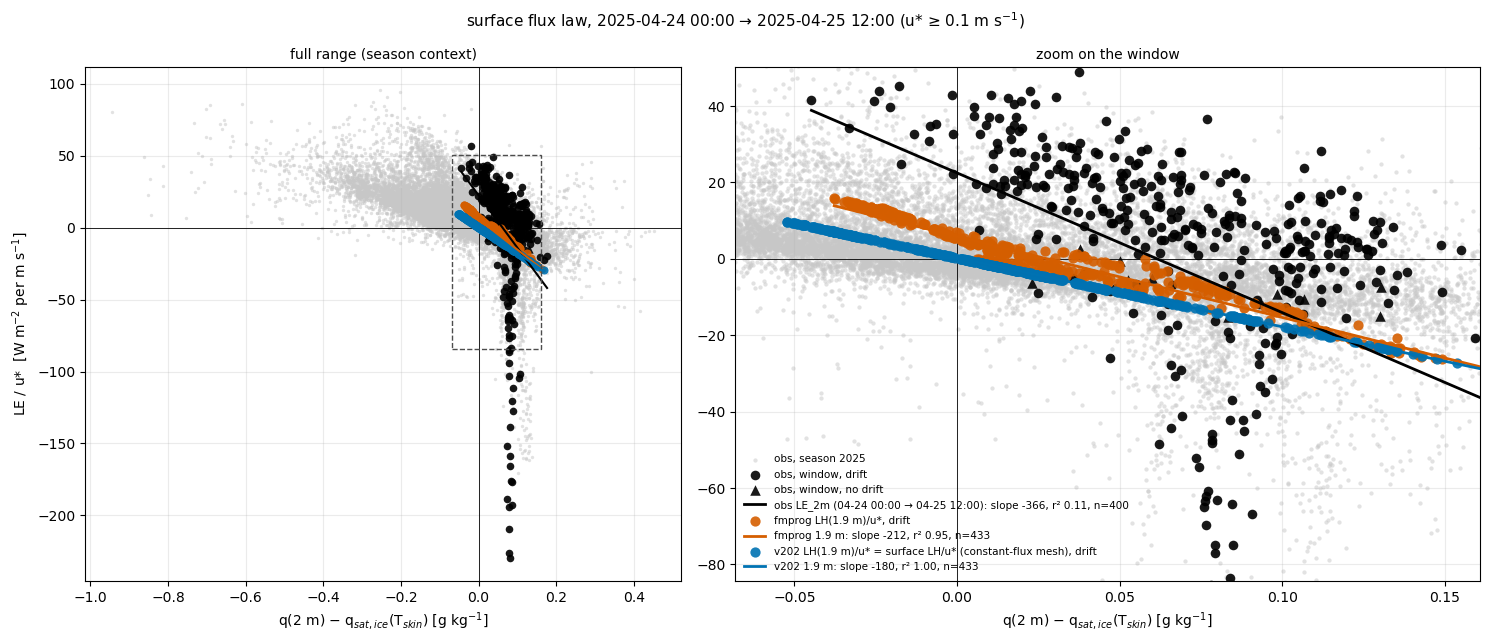

,series,slope,intercept,r2,n
0,obs LE_2m (04-24 00:00 → 04-25 12:00),-365.65,22.51,0.11,400
1,fmprog 1.9 m,-212.28,5.90,0.95,433
2,fmprog no-drift steps in window,NaN,NaN,NaN,0
3,v202 1.9 m,-180.27,0.25,1.00,433
4,v202 no-drift steps in window,NaN,NaN,NaN,0


,fmprog,v202
"particle term / u*, median",5.57,9.46
std,3.14,4.47
corr with surface excess x,-0.55,-0.59
corr with drift flux,-0.18,0.02
corr with air excess x_air,-0.92,-0.86
median x_air [g/kg],-0.03,-0.04
median T_air − T_skin [K],0.36,0.40


In [257]:
"""SURFACE FLUX LAW, MODEL VS OBS for the CRYOWRF 'ws' event (`sfl_window`). Same axes as the cell above,
2 m probe only. Grey: all 2025 obs. Coloured: obs in the window (circle drift, triangle no drift). Model runs
(fmprog, v202) from `sfl_model_csv`: filled = LH at 1.9 m (surface LH + blowing-snow sublimation below the
sensor, like-for-like with the 1.9 m sonic). In v202 the T/q mesh is a constant-flux diagnostic profile and the
particle vapour is injected at the first WRF level, so its 1.9 m flux equals its surface flux (labelled so).
`show_surface=True` adds the surface LH alone as open markers where it differs (fmprog); the gap is the latent
heat exchanged on particles below the sensor, which the obs cannot separate. The table after the figure tests
what sets the particle term (LH_PART_1.9m): the air's undersaturation at its own temperature, not the surface excess. The CSV is produced on CSCS from the
fm_prognostic column tools; if it is missing the cell draws the observations only."""

sfl_model = None
if sfl_model_csv is not None and os.path.exists(sfl_model_csv):
    sfl_model = load_model_flux_law(sfl_model_csv, kw_ec, drift_threshold=sfl_model_drift_thr, ustar_min=sfl_ustar_min)
    print(f'model: {sfl_model.index.min()} → {sfl_model.index.max()}, runs {sorted(sfl_model.run.unique())}, '
          f'no-drift steps per run: {sfl_model.groupby("run")["drift"].apply(lambda s: int((s == False).sum())).to_dict()}')
else:
    print(f'no model CSV at {sfl_model_csv}: observations only')

fig, axes, sfl_mo_fits = plot_flux_law_model_vs_obs(tab, sfl_window, model=sfl_model, q_level='2m', ustar_min=sfl_ustar_min,
                                                    show_surface=False)   # True adds the model's surface LH/u* as open markers
plt.show()
display(sfl_mo_fits.round(2))
if sfl_model is not None:
    # why the 1.9 m flux scatters about the law while the surface flux does not: the particle term follows
    # the air's undersaturation at its own temperature (x_air, v2 export), not the surface excess
    display(model_particle_term_check(sfl_model, sfl_window).round(2))


## 6. Water vapour budget of the layers

After Schwat et al. (2025, *J. Hydrometeor.*, Eq. 4): `residual = storage + turbulent flux divergence + vertical advection`, in mg m⁻³ s⁻¹. If the residual stays positive during blowing snow while storage and vertical advection are small, the divergence is not explained by transport and points to a vapour source in the layer (sublimation of suspended snow). Horizontal advection is not measured and ends up in the residual.

Limits of this estimate at PEA in 2025: humidity is measured at only two heights (2 m and 26 m), so the storage term is a two-point mean and the humidity gradient is a log profile through two points. The mean vertical wind comes from a sectorial planar fit of the 1 min logger sonic means at 2 m and 26 m. Treat vertical advection as an order-of-magnitude estimate. Run the *budget prep* cell first; the two plot cells need it.

In [258]:
"""BUDGET PREP: storage, turbulent flux divergence, vertical advection and residual per layer"""

budget = vapour_budget(tab, slow_sfc, slow_upper, sonic_heights, th_heights, kw_met=kw_temp,
                       pairs=div_pairs, n_sectors=budget_n_sectors)

terms = ['storage'] + [f'{t}_{p}' for p in pair_tags for t in ('vtfd', 'vadv', 'res')]
print('mean vertical wind after planar fit [cm/s]:  2 m  median |w| = '
      f'{budget["w_2m"].abs().median() * 100:.1f},  26 m  median |w| = {budget["w_26m"].abs().median() * 100:.1f}')
budget[terms].describe().loc[['count', '25%', '50%', '75%']].round(3)

mean vertical wind after planar fit [cm/s]:  2 m  median |w| = 1.0,  26 m  median |w| = 3.4


,storage,vtfd_16_2,vadv_16_2,res_16_2,vtfd_26_2,vadv_26_2,res_26_2,vtfd_26_16,vadv_26_16,res_26_16
count,36554.000,31350.000,36332.000,31178.000,32601.000,36332.000,32431.000,30712.000,36332.000,30551.000
25%,-0.013,-0.017,-0.019,-0.029,-0.009,-0.016,-0.021,-0.006,-0.015,-0.019
50%,-0.000,0.003,-0.000,0.003,0.004,0.000,0.006,0.007,0.000,0.011
75%,0.013,0.027,0.018,0.044,0.024,0.017,0.044,0.036,0.018,0.056


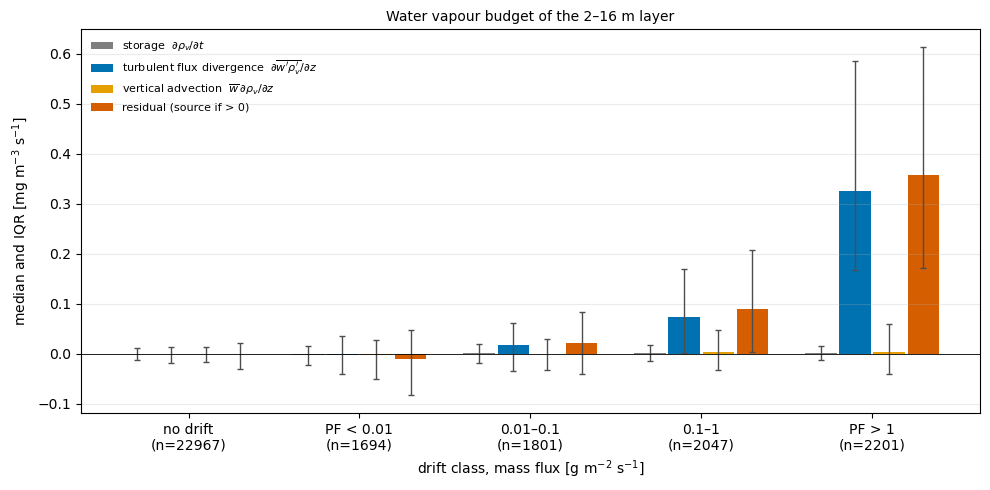

,n,storage,vtfd,vadv,res
drift,,,,,
no drift,22967,-0.001,0.000,-0.000,-0.002
PF < 0.01,1694,-0.002,-0.002,-0.003,-0.010
0.01–0.1,1801,0.001,0.017,-0.001,0.021
0.1–1,2047,0.001,0.073,0.004,0.089
PF > 1,2201,0.002,0.325,0.003,0.357


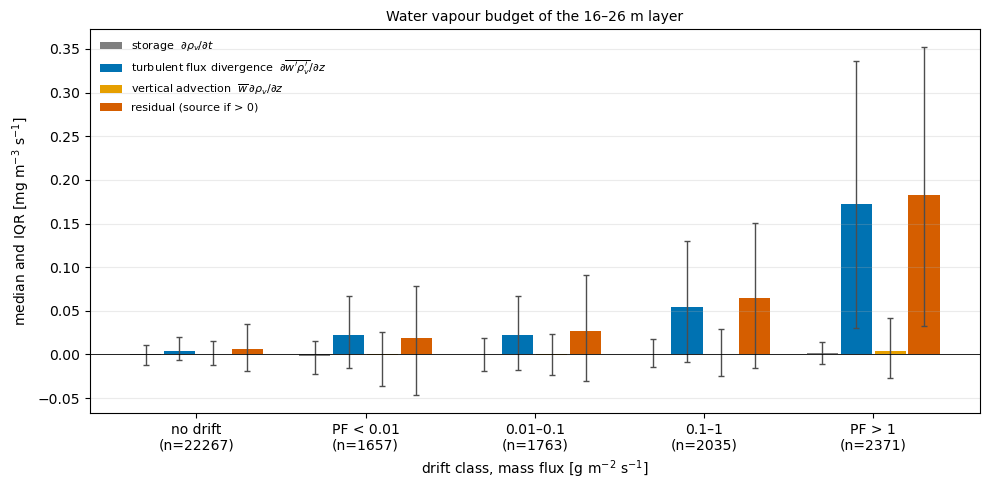

,n,storage,vtfd,vadv,res
drift,,,,,
no drift,22267,-0.001,0.004,0.000,0.006
PF < 0.01,1657,-0.002,0.022,-0.001,0.019
0.01–0.1,1763,0.001,0.022,-0.000,0.027
0.1–1,2035,0.001,0.055,0.001,0.065
PF > 1,2371,0.001,0.172,0.005,0.183


In [259]:
"""BUDGET BY DRIFT INTENSITY (needs budget prep): median terms per drift class, per layer"""

for pair in ['16_2', '26_16']:
    if pair not in pair_tags:
        continue
    fig, ax, budget_by_drift = plot_budget_by_drift(budget, tab, pair)
    plt.show()
    display(budget_by_drift.round(3))

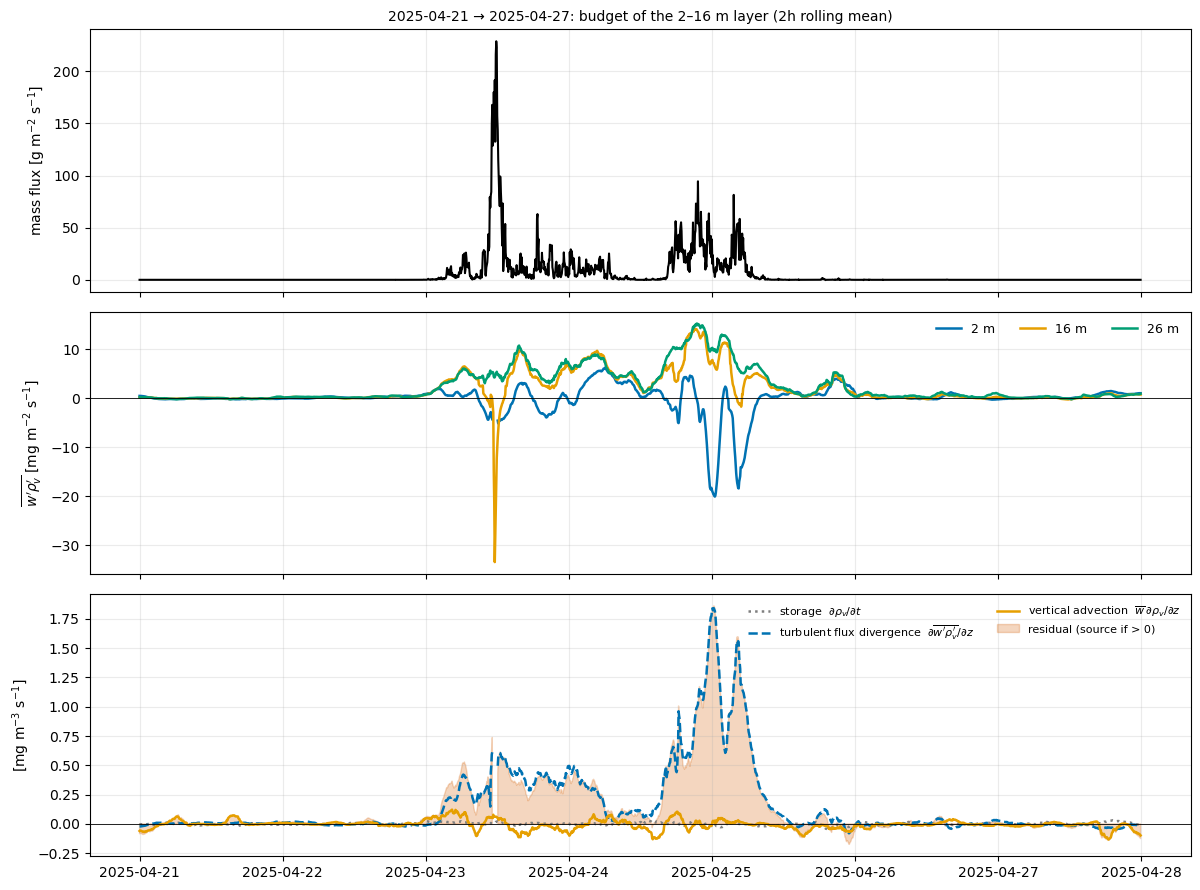

In [260]:
"""BUDGET EVENT TIME SERIES (needs budget prep): drift flux, vapour flux per level and budget terms
of the 2–16 m layer for the window `budget_event` (compare Schwat et al. 2025, Fig. 6)"""

fig, axes = plot_budget_event(budget, tab, *budget_event, pair='16_2', height_colors={'2m': colors['SFC'], '16m': colors['16m'], '26m': colors['26m']})
plt.show()

## 7. Which variable matters most? Driver ranking

A gradient-boosted model predicts `dLE` from all drivers. Skill is the R² of predictions for held-out week-long blocks (out-of-fold R²). Importance is the drop in that R² when all variables of one group are shuffled together. **Read the importance only where the out-of-fold R² is clearly above zero**; with no skill there is nothing to attribute.

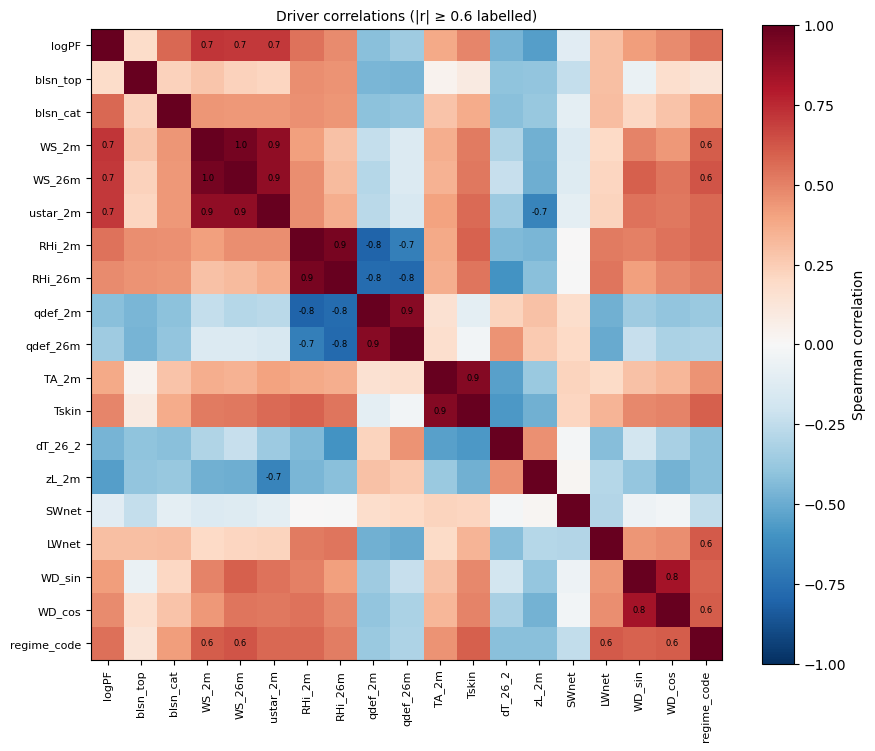

In [261]:
"""DRIVER CORRELATIONS (Spearman): which drivers cannot be separated from each other"""

corr = driver_correlation(tab, driver_groups)
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=8)
ax.set_yticks(range(len(corr)), corr.index, fontsize=8)
for i in range(len(corr)):
    for j in range(len(corr)):
        if i != j and abs(corr.values[i, j]) >= 0.6:
            ax.text(j, i, f'{corr.values[i, j]:.1f}', ha='center', va='center', fontsize=6)
fig.colorbar(im, ax=ax, label='Spearman correlation')
ax.set_title('Driver correlations (|r| ≥ 0.6 labelled)', fontsize=10)
plt.tight_layout()
plt.show()

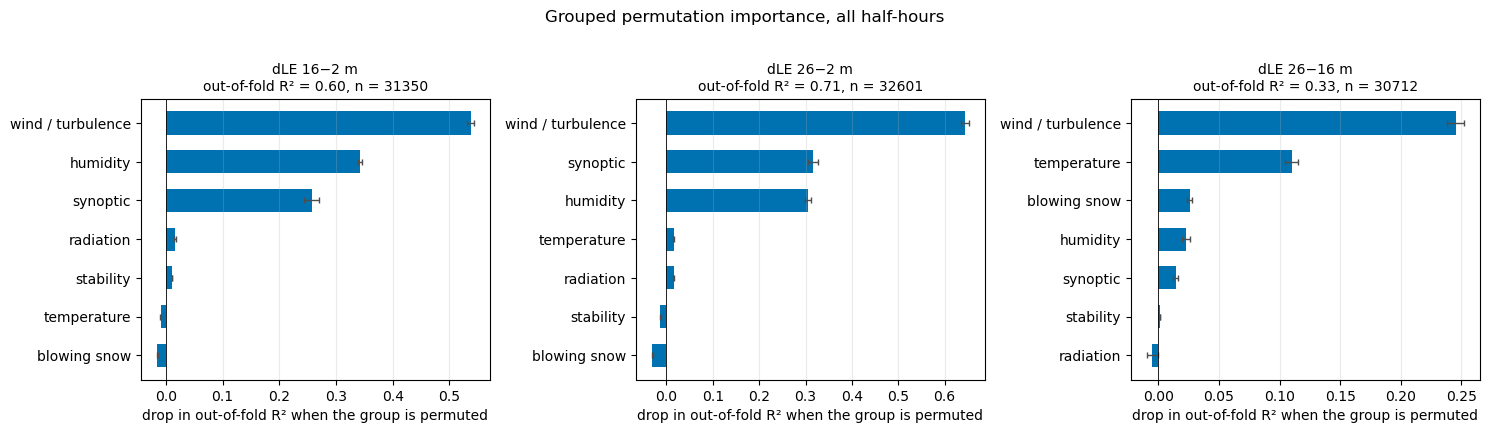

In [262]:
"""RANKING CELL: fit and rank per pair, on all half-hours (about half a minute)"""

rank_kw = dict(block=div_cv_block, n_splits=div_cv_splits, n_repeats=div_n_repeats)
ranks = {pair: rank_divergence_drivers(tab, f'dLE_{pair}', driver_groups, **rank_kw) for pair in pair_tags}

for p_, r_ in ranks.items():
    if r_ is None:
        print(f'dLE {p_}: fewer than 300 valid half-hours, not fitted')
fig, axes = plot_importance({f'dLE {p.replace("_", "−")} m': r for p, r in ranks.items()},
                            title='Grouped permutation importance, all half-hours')
plt.show()

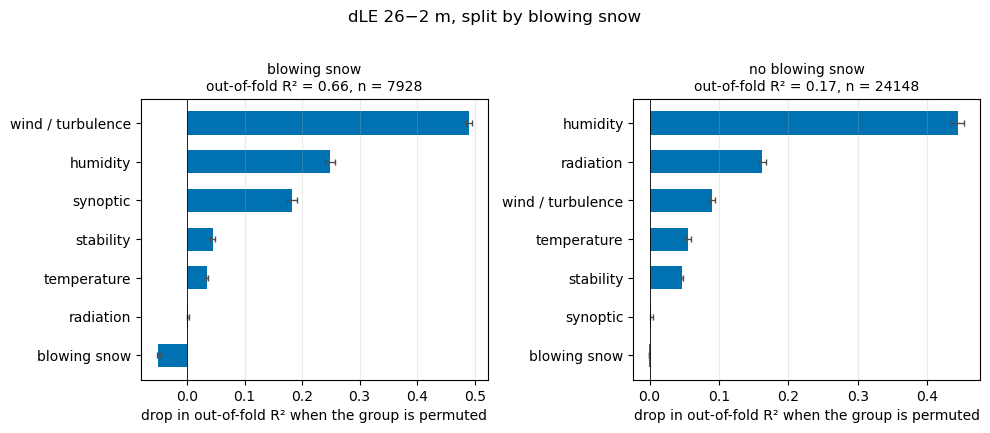

In [263]:
"""RANKING SPLIT BY BLOWING SNOW for the focus pair: does the dominant driver change?"""

rank_kw = dict(block=div_cv_block, n_splits=div_cv_splits, n_repeats=div_n_repeats)
ranks_split = {
    'blowing snow':    rank_divergence_drivers(tab[tab['bs'] == True],  f'dLE_{focus_pair}', driver_groups, **rank_kw),
    'no blowing snow': rank_divergence_drivers(tab[tab['bs'] == False], f'dLE_{focus_pair}', driver_groups, **rank_kw),
}
for k, r in ranks_split.items():
    if r is None:
        n_k = int(tab.loc[tab['bs'] == (k == 'blowing snow'), f'dLE_{focus_pair}'].notna().sum())
        print(f'{k}: only {n_k} valid half-hours, at least 300 are needed to fit')
fig, axes = plot_importance(ranks_split, title=f'dLE {focus_pair.replace("_", "−")} m, split by blowing snow')
plt.show()

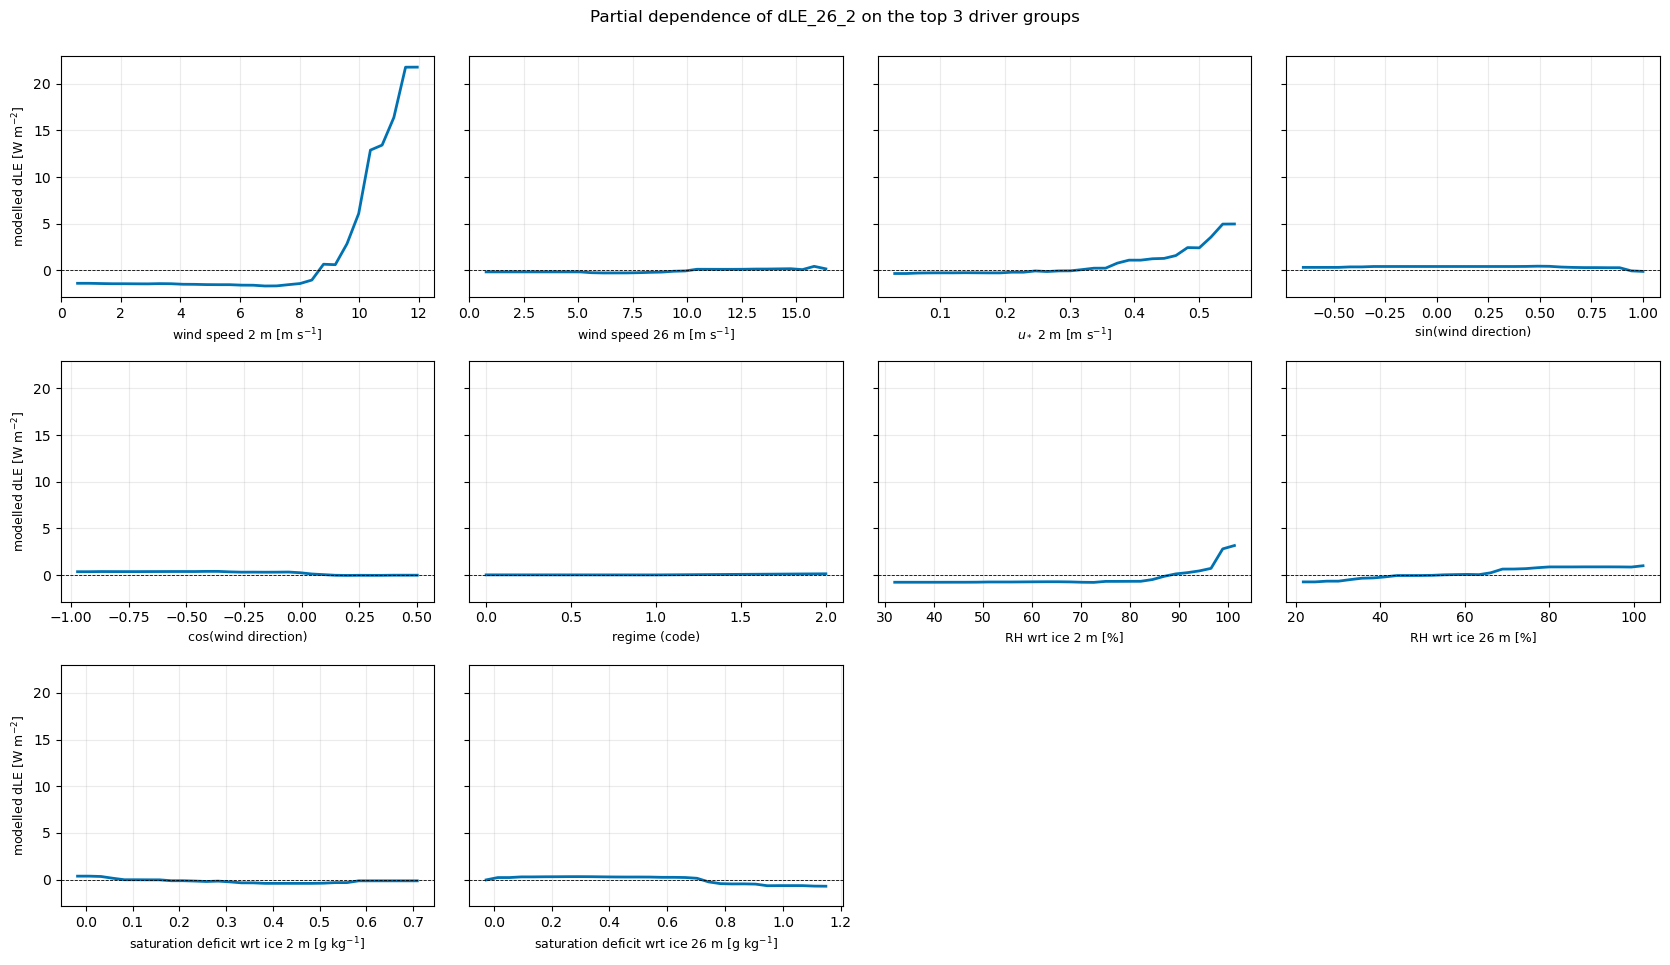

In [264]:
"""PARTIAL DEPENDENCE for the focus pair (needs the ranking cell): how modelled dLE changes with each
variable of the three most important groups, other variables averaged out"""

if ranks[focus_pair] is None:
    print(f'No model for dLE {focus_pair}: too few valid half-hours.')
else:
    fig, axes = plot_partial_dependence(ranks[focus_pair], driver_groups, n_groups=3)
    plt.show()

## 8. Summary

In [265]:
"""SUMMARY TABLE per pair (needs the ranking cell)"""

rows = {}
for pair in pair_tags:
    cat, bs = cats[pair], tab['bs']
    share = lambda name, m: (cat[m] == name).sum() / cat[m].notna().sum()
    r = ranks[pair]
    rows[pair.replace('_', '−') + ' m'] = {
        'noise floor [W m-2]': round(noise_thr[pair], 1),
        'divergent, blowing snow': f"{share('divergent', bs == True):.0%}",
        'divergent, no blowing snow': f"{share('divergent', bs == False):.0%}",
        'convergent, blowing snow': f"{share('convergent', bs == True):.0%}",
        'convergent, no blowing snow': f"{share('convergent', bs == False):.0%}",
        'out-of-fold R²': f"{float(np.mean(r['r2'])):.2f}" if r else 'n/a',
        'top driver groups': ', '.join(r['importance'].index[:3]) if has_skill(r) else 'no skill, not ranked',
    }
pd.DataFrame(rows)

,16−2 m,26−2 m,26−16 m
noise floor [W m-2],4.1,4.9,2.9
"divergent, blowing snow",39%,42%,30%
"divergent, no blowing snow",1%,2%,2%
"convergent, blowing snow",7%,6%,7%
"convergent, no blowing snow",2%,2%,1%
out-of-fold R²,0.60,0.71,0.33
top driver groups,"wind / turbulence, humidity, synoptic","wind / turbulence, synoptic, humidity","wind / turbulence, temperature, blowing snow"


## 9. Numbers for the paper text

Every number quoted in the measurement results (draft section 3.1), on 30 min means. Needs only the config and load cells.

In [266]:
"""PAPER NUMBERS: every number quoted in the measurement results text, on 30 min means because the
text speaks of half-hours and defines drift on 30 min means: FlowCapt mass flux above `paper_drift_thr`
with the 2 m wind speed above `paper_drift_ws_min`. The cell builds its own 30 min
table from the loaded data, so it does not depend on the 5 min `tab` or on any analysis cell. The LI-7500
diagnostic comes from the cache in `agc_cache_dir`. The planar fit for the advection terms takes about a minute.
The sublimated mass is integrated over the 5 min EddyPro fluxes as read (no resampling, no gap filling),
with drift taken from the 30 min table so that it follows the paper definition."""

kw30 = lambda kw: dict(kw, resample_time=paper_resample)
tab30 = build_divergence_table(
    fluxes={'2m': fluxes_sfc, '16m': fluxes_low, '26m': fluxes_up},
    sonic_heights=sonic_heights,
    slow_sfc=slow_sfc, slow_upper=slow_upper, blsn_alg=blsn_alg, cluster=cluster,
    start=div_start, end=div_end, kw_ec=kw30(kw_ec), kw_met=kw30(kw_temp), kw_bs=kw30(kw_bs), kw_blsn=kw30(kw_blsn),
    pairs=div_pairs, bs_threshold=div_bs_threshold, wd_exclude=div_wd_exclude, drift_ws_min=div_drift_ws_min,
)
tab30 = add_stability_class(tab30, zL_neutral)
noise_mask30 = (tab30['PF_FC4'] == 0) & (tab30['stability'] == 'neutral')
noise_thr30 = {p: classify_divergence(tab30, p, noise_mask30, div_noise_quantile)[0] for p in pair_tags}

diag30 = {lvl: li7500_diag_halfhourly(folder_ec, sensor, div_start, div_end,
                                      cache_file=f'{agc_cache_dir}/li7500_diag_{sensor}_{year}.csv', verbose=False)
          for lvl, sensor in [('2m', 'SFC'), ('16m', 'LOWER'), ('26m', 'UPPER')]}
budget30 = vapour_budget(tab30, slow_sfc, slow_upper, sonic_heights, th_heights, kw_met=kw30(kw_temp),
                         pairs=div_pairs, n_sectors=budget_n_sectors)
energy30 = layer_energy_terms(tab30, budget30, slow_sfc, slow_upper, sonic_heights, th_heights,
                              kw_met=kw30(kw_temp), pairs=div_pairs)

paper_nums, paper_tables = paper_numbers(
    tab30, noise_thr30, diag30, energy=energy30, flip_pairs=flip_pairs,
    drift_thr=paper_drift_thr, strong_thr=paper_strong_thr, event_gap=paper_event_gap,
    profile_edges=profile_pf_edges, ws_edges=paper_ws_edges, ws_min=paper_ws_min,
    max_share=agc_max_share, zL_neutral=zL_neutral, drift_ws_min=paper_drift_ws_min, ws_col='WS_2m',
)
drift30 = ((tab30['PF_FC4'] > paper_drift_thr) & (tab30['WS_2m'] > paper_drift_ws_min)).astype(float)
drift30 = drift30.where(tab30['PF_FC4'].notna() & tab30['WS_2m'].notna())   # unknown where either is missing
mass_5min = sublimated_mass_5min({'2m': fluxes_sfc, '16m': fluxes_low, '26m': fluxes_up},
                                 drift30=drift30, ta=slow_sfc['TA'], start=div_start, end=div_end)
paper_nums = pd.concat([paper_nums, mass_5min])

with pd.option_context('display.max_rows', None, 'display.max_colwidth', 100):
    display(paper_nums)
    display(paper_tables['profile'].round(2))
    display(paper_tables['energy'].round(2))


value  \
section                        quantity                                                                                                                                               
window                         start                                                                                                                            2025-02-20 00:00:00   
                               end                                                                                                                              2025-06-26 23:30:00   
                               interval                                                                                                                             0 days 00:30:00   
noise floor                    90th pct |dLE| 16_2, no drift and neutral                                                                                                      3.397   
                               90th pct |dLE| 26_2, no drift and neutral                                                                                                      3.822   
                               90th pct |dLE| 26_16, no drift and neutral                                                                                                     1.786   
drift occurrence               intervals with FlowCapt data                                                                                                                    6092   
                               share PF > 0.001 (any wind)                                                                                                                    0.247   
                               share PF > 0.001, WS_2m > 5 m/s                                                                                                                0.231   
                               share PF > 1, WS_2m > 5 m/s                                                                                                                    0.076   
                               share PF > 0 in wind <= 5 m/s (neither drift nor no drift)                                                                                     0.033   
events                         events (PF > 0.001, WS_2m > 5 m/s, gaps <= 2h merged)                                                                                             71   
                               events longer than 12 h                                                                                                                           14   
                               events longer than 24 h                                                                                                                            9   
no drift                       intervals (PF = 0, LE valid at 3 levels)                                                                                                        2504   
                               mean LE 2m                                                                                                                                     0.808   
                               mean LE 16m                                                                                                                                    0.624   
                               mean LE 26m                                                                                                                                    0.815   
                               mean dLE 16_2                                                                                                                                 -0.184   
                               mean dLE 26_2                                                                                                                                  0.008   
                               mean dLE 26_16                                                                                                       

,n,LE_2m,LE_16m,LE_26m,RHi_2m,RHi_26m,WS_2m,share LE_2m < 0,share LE_26m > 0
bin,,,,,,,,,
0,2504,0.81,0.62,0.82,57.98,44.61,3.60,0.37,0.81
0.001–0.01,195,3.08,2.86,3.51,74.70,60.02,6.17,0.24,0.87
0.01–0.1,309,2.64,3.15,3.82,78.59,64.48,6.76,0.29,0.90
0.1–0.3,159,3.25,5.17,6.09,83.62,70.29,7.74,0.31,1.00
0.3–1,162,3.23,8.84,10.64,87.76,76.46,8.89,0.37,1.00
1–3,168,-1.36,10.06,13.34,92.40,83.93,9.97,0.54,1.00
3–10,142,-6.32,11.32,16.39,94.20,86.16,11.27,0.60,1.00
10–30,60,-8.04,17.99,22.67,93.13,80.92,12.42,0.52,1.00
30–100,12,-19.83,16.21,23.37,96.32,88.42,13.16,0.67,1.00


,wsb,n,dLE,dH,dSum,stor,adv,res,pair
0,"(4, 6]",165,-0.17,4.96,4.99,-0.07,1.38,8.29,16_2
1,"(6, 8]",427,0.62,3.07,4.58,0.32,0.25,5.95,16_2
2,"(8, 10]",308,4.59,-6.41,0.18,0.34,3.21,3.61,16_2
3,"(10, 12]",219,13.17,-13.99,0.99,0.29,5.41,8.24,16_2
4,"(12, 14]",78,22.91,-23.21,1.63,0.09,1.79,6.15,16_2
5,"(4, 6]",150,0.58,1.07,1.39,0.16,-0.96,1.37,26_16
6,"(6, 8]",397,0.58,3.10,3.69,0.18,-0.69,2.96,26_16
7,"(8, 10]",299,1.97,3.46,5.77,0.16,1.12,7.16,26_16
8,"(10, 12]",218,4.54,2.93,7.61,0.17,1.63,8.41,26_16
9,"(12, 14]",79,6.48,7.92,13.80,0.07,1.70,14.29,26_16


In [ ]:
"""VAPOUR FLUX PER LEVEL (LaTeX table): integrated 5 min EddyPro LE [mm w.e.] at 2, 16 and 26 m, net
(`subl_positive_only = False`: deposition subtracted, so 26 m - 2 m is the vapour source in the layer, as in the
paper text) or sublimation only (`True`: negative LE counted as zero; then level differences are not a layer source), summed over the 5 min intervals in which LE is valid at
all three levels, so the levels are compared on the same samples. Split by the 30 min drift flag `drift30` of the
cell above (FlowCapt > `paper_drift_thr` and 2 m wind > `paper_drift_ws_min`). Prints the LaTeX code to paste."""

subl_positive_only = False
subl_table, subl_info = sublimation_per_level_5min(
    {'2m': fluxes_sfc, '16m': fluxes_low, '26m': fluxes_up}, ta=slow_sfc['TA'],
    start=div_start, end=div_end, drift30=drift30, positive_only=subl_positive_only)
print(sublimation_latex(subl_table, subl_info, label='tab:sublimation_levels'))
subl_table.round(2)

In [267]:
import sys
_m = sys.modules.get('ec.func_flux_divergence')
print('module file:', getattr(_m, '__file__', None))
print('module has MODEL_CSV_OPTIONAL:', hasattr(_m, 'MODEL_CSV_OPTIONAL'), '| has MODEL_CSV_COLUMNS:', hasattr(_m, 'MODEL_CSV_COLUMNS'))
f = globals().get('load_model_flux_law')
print('user-ns function:', f, '| code file:', f.__code__.co_filename if f else None, '| func globals is module dict:', (f.__globals__ is _m.__dict__) if (f and _m) else None)
print('func globals has MODEL_CSV_OPTIONAL:', ('MODEL_CSV_OPTIONAL' in f.__globals__) if f else None, '| func globals __name__:', f.__globals__.get('__name__') if f else None)
print('module.load_model_flux_law is user-ns one:', (getattr(_m, 'load_model_flux_law', None) is f))
print('other ec modules loaded:', [k for k in sys.modules if k.startswith('ec') or k == 'utils' or k.startswith('utils.')])
print('autoreload loaded:', 'IPython.extensions.autoreload' in sys.modules, '| IPython', __import__('IPython').__version__)

module file: /home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_flux_divergence.py
module has MODEL_CSV_OPTIONAL: True | has MODEL_CSV_COLUMNS: True
user-ns function: <function load_model_flux_law at 0x7bdb6fba34c0> | code file: /home/engbers/Documents/Github/DataProcessingScripts/src/ec/func_flux_divergence.py | func globals is module dict: True
func globals has MODEL_CSV_OPTIONAL: True | func globals __name__: ec.func_flux_divergence
module.load_model_flux_law is user-ns one: True
other ec modules loaded: ['utils.constants', 'utils.utils', 'utils', 'ec.func_read_data', 'ec.func_despike_data', 'ec.sensor_info', 'ec.func_dr', 'ec.func_mrfd', 'ec.func_coherence', 'ec', 'ec.func_flux_divergence']
autoreload loaded: True | IPython 9.5.0


In [268]:
fluxes_sfc['LE'].isna().sum()/fluxes_sfc['LE'].count(), fluxes_low['LE'].isna().sum()/fluxes_low['LE'].count(), fluxes_up['LE'].isna().sum()/fluxes_up['LE'].count()

(0.12016978050147246, 0.26289714912931267, 0.48910868446629696)

In [269]:
fluxes_low

,Tau,qc_Tau,H,qc_H,LE,qc_LE,h2o_flux,qc_h2o_flux,H_strg,LE_strg,...,w_spikes,ts_spikes,h2o_spikes,u_var,v_var,w_var,ts_var,h2o_var,w/ts_cov,w/h2o_cov
datetime,,,,,,,,,,,,,,,,,,,,,
2025-02-11 11:00:00,0.039544,1.0,NaN,2.0,0.986449,1.0,0.019298,1.0,NaN,NaN,...,0.0,0.0,0.0,0.022289,0.400499,0.009540,0.007070,1.40404,-0.001020,0.012001
2025-02-11 11:05:00,-0.008169,1.0,20.66420,1.0,-0.377272,1.0,-0.007381,1.0,38.6779,-0.341243,...,0.0,0.0,0.0,0.088523,0.071887,0.017438,0.129955,1.18063,0.015692,-0.016536
2025-02-11 11:10:00,-0.074361,1.0,15.02470,0.0,15.626070,0.0,0.305721,0.0,30.7354,4.419180,...,0.0,0.0,0.0,0.162313,0.148312,0.093546,0.137942,6.06071,0.011309,0.231656
2025-02-11 11:15:00,-0.035807,1.0,19.73200,1.0,8.347671,1.0,0.163313,1.0,-37.6938,-5.008380,...,0.0,0.0,0.0,0.365898,0.801147,0.031188,0.264977,3.05491,0.015221,0.125405
2025-02-11 11:20:00,0.045484,1.0,NaN,2.0,NaN,2.0,0.057677,2.0,-27.7722,2.298640,...,0.0,0.0,0.0,0.075501,0.155882,0.021621,0.015083,7.44684,-0.002442,0.048697
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-12-31 23:35:00,-0.055075,0.0,-15.82470,0.0,NaN,2.0,-0.043183,2.0,-17.8097,-2.638000,...,0.0,0.0,0.0,0.328328,0.637589,0.066510,0.641399,4.08731,-0.014260,-0.043164
2025-12-31 23:40:00,-0.026474,0.0,-5.61503,1.0,2.268663,0.0,0.044386,0.0,-41.5222,8.955290,...,0.0,0.0,0.0,0.209545,0.323789,0.042508,0.211174,3.25564,-0.004925,0.039907
2025-12-31 23:45:00,-0.132999,1.0,-50.39180,1.0,8.866553,1.0,0.173479,1.0,34.5773,-1.240180,...,0.0,0.0,0.0,1.377500,0.487478,0.087805,0.408104,9.43485,-0.044755,0.171479
